# California Housing Price Prediction — OLS vs Ridge vs Lasso

**Goal:** predict `median_house_value` for California census block groups with a leakage-free regression workflow:
imputation → feature engineering → multicollinearity diagnosis → regularised models tuned with `GridSearchCV` →
residual analysis.

| # | Section | Key question |
|---|---|---|
| 1 | Load & audit | What is in the data, and what is wrong with it? |
| 2 | EDA & correlation heatmap | Which features matter, and which are redundant? |
| 3 | Train/test split | 80/20, stratified on income so both sets look alike |
| 4 | Imputation | Does the way we fill the 207 missing `total_bedrooms` matter? (paired CV comparison) |
| 5 | Multicollinearity | VIF + condition number, before and after engineering |
| 6 | Feature-engineering ablation | Which engineered features actually help (judged by CV, not by the test set)? |
| 7 | OLS / Ridge / Lasso + `GridSearchCV` | Tune α on the 18-feature pipeline, CV curves, regularisation paths |
| 8 | Stress test: degree-3 polynomials | 168 collinear features — where L1/L2 genuinely matter |
| 9 | Test-set benchmark | RMSE, MAE, R² for all six models + paired bootstrap CIs |
| 10 | Coefficients & sparsity | What did L1 and L2 do to the weights? |
| 11 | Residual analysis | Predicted-vs-actual, residual distributions, Q-Q, spatial & heteroscedasticity checks |
| 12 | Extension: log-target | Does the residual analysis suggest a fix? |
| 13 | Extension: small-sample regime | Regularisation as a small-data tool |
| 14 | Conclusions | |

**Conventions.** The target is modelled in units of **$100,000** so regularisation strengths are easy to read; every reported
error metric is converted back to **dollars**. All preprocessing lives inside a `Pipeline`, so imputation statistics and scaler
parameters are learned from training folds only.

## 0. Setup

In [1]:
import warnings, tempfile
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV, lasso_path
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

RANDOM_STATE = 42
SCALE = 100_000          # target is modelled in $100k units; metrics are reported in dollars
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 1. Load and audit the data

Source: the classic *Hands-On ML* copy of the 1990 California census (20,640 block groups). Each row is a **block group**, so
`total_rooms`, `population`, etc. are *counts for the whole block group*, not per-house values — an important modelling detail.

In [2]:
URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
try:
    df = pd.read_csv(URL)
    source = "URL"
except Exception:
    df = pd.read_csv("housing.csv")      # local copy fallback
    source = "local file"
print(f"Loaded from {source}: shape = {df.shape}")
df.head()

Loaded from URL: shape = (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.2300,37.8800,41.0000,880.0000,129.0000,322.0000,126.0000,8.3252,"452,600.0000",NEAR BAY
1,-122.2200,37.8600,21.0000,"7,099.0000","1,106.0000","2,401.0000","1,138.0000",8.3014,"358,500.0000",NEAR BAY
2,-122.2400,37.8500,52.0000,"1,467.0000",190.0000,496.0000,177.0000,7.2574,"352,100.0000",NEAR BAY
3,-122.2500,37.8500,52.0000,"1,274.0000",235.0000,558.0000,219.0000,5.6431,"341,300.0000",NEAR BAY
4,-122.2500,37.8500,52.0000,"1,627.0000",280.0000,565.0000,259.0000,3.8462,"342,200.0000",NEAR BAY


In [3]:
audit = pd.DataFrame({"dtype": df.dtypes.astype(str), "n_missing": df.isna().sum(),
                      "pct_missing": df.isna().mean() * 100, "n_unique": df.nunique()})
display(audit)
display(df.describe().T)
print("\nocean_proximity counts:"); display(df["ocean_proximity"].value_counts().to_frame("rows"))

,dtype,n_missing,pct_missing,n_unique
longitude,float64,0,0.0000,844
latitude,float64,0,0.0000,862
housing_median_age,float64,0,0.0000,52
total_rooms,float64,0,0.0000,5926
total_bedrooms,float64,207,1.0029,1923
population,float64,0,0.0000,3888
households,float64,0,0.0000,1815
median_income,float64,0,0.0000,12928
median_house_value,float64,0,0.0000,3842
ocean_proximity,str,0,0.0000,5


,count,mean,std,min,25%,50%,75%,max
longitude,"20,640.0000",-119.5697,2.0035,-124.3500,-121.8000,-118.4900,-118.0100,-114.3100
latitude,"20,640.0000",35.6319,2.1360,32.5400,33.9300,34.2600,37.7100,41.9500
housing_median_age,"20,640.0000",28.6395,12.5856,1.0000,18.0000,29.0000,37.0000,52.0000
total_rooms,"20,640.0000","2,635.7631","2,181.6153",2.0000,"1,447.7500","2,127.0000","3,148.0000","39,320.0000"
total_bedrooms,"20,433.0000",537.8706,421.3851,1.0000,296.0000,435.0000,647.0000,"6,445.0000"
population,"20,640.0000","1,425.4767","1,132.4621",3.0000,787.0000,"1,166.0000","1,725.0000","35,682.0000"
households,"20,640.0000",499.5397,382.3298,1.0000,280.0000,409.0000,605.0000,"6,082.0000"
median_income,"20,640.0000",3.8707,1.8998,0.4999,2.5634,3.5348,4.7432,15.0001
median_house_value,"20,640.0000","206,855.8169","115,395.6159","14,999.0000","119,600.0000","179,700.0000","264,725.0000","500,001.0000"



ocean_proximity counts:


,rows
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


### 1.1 Data-quality findings

- **Only one column has nulls:** `total_bedrooms` (207 rows, ≈1 %).
- **`ocean_proximity` is categorical** (5 levels, `ISLAND` has just 5 rows) → one-hot encoding.
- **The target is right-censored.** House values are capped at \$500,001 and `housing_median_age` is capped at 52. Let's quantify it.

Target cap = 500,001 → 965 block groups (4.7%) sit exactly at the cap
Block groups with housing_median_age == 52: 1273


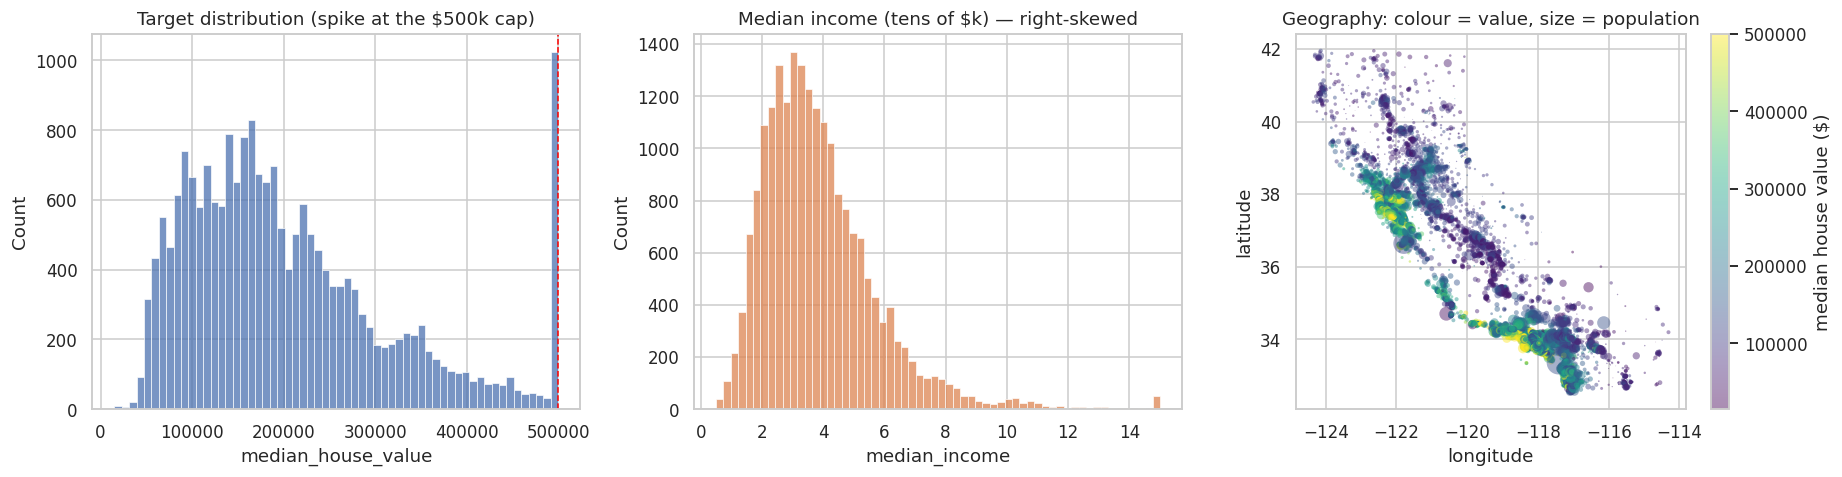

In [4]:
cap_val = df["median_house_value"].max()
n_cap = (df["median_house_value"] == cap_val).sum()
print(f"Target cap = {cap_val:,.0f} → {n_cap} block groups ({n_cap/len(df):.1%}) sit exactly at the cap")
print(f"Block groups with housing_median_age == 52: {(df.housing_median_age == 52).sum()}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(df["median_house_value"], bins=60, ax=axes[0], color="C0")
axes[0].axvline(cap_val, color="red", ls="--", lw=1); axes[0].set_title("Target distribution (spike at the $500k cap)")

sns.histplot(df["median_income"], bins=60, ax=axes[1], color="C1")
axes[1].set_title("Median income (tens of $k) — right-skewed")

sc = axes[2].scatter(df.longitude, df.latitude, c=df.median_house_value, s=df.population / 150,
                     cmap="viridis", alpha=.45, linewidths=0)
axes[2].set_xlabel("longitude"); axes[2].set_ylabel("latitude"); axes[2].set_title("Geography: colour = value, size = population")
plt.colorbar(sc, ax=axes[2], label="median house value ($)")
plt.tight_layout(); plt.show()

The map is the single most important picture in this dataset: **price is strongly spatial** (coastal Bay Area and Los Angeles are
expensive, the Central Valley is cheap). A linear model on raw latitude/longitude can only capture a tilted plane — we will come back
to this limitation in the residual analysis.

**Consequence of censoring:** about 4.7 % of rows have a true value *above* \$500k that we only observe as \$500,001. Linear models
will systematically under-predict those rows. We keep them (they are part of the benchmark) but report an *uncapped-rows-only* metric
later so the effect is visible.

## 2. Exploratory analysis and correlation heatmap

Correlations below use pairwise-complete observations (so the 207 missing `total_bedrooms` do not need to be filled yet).

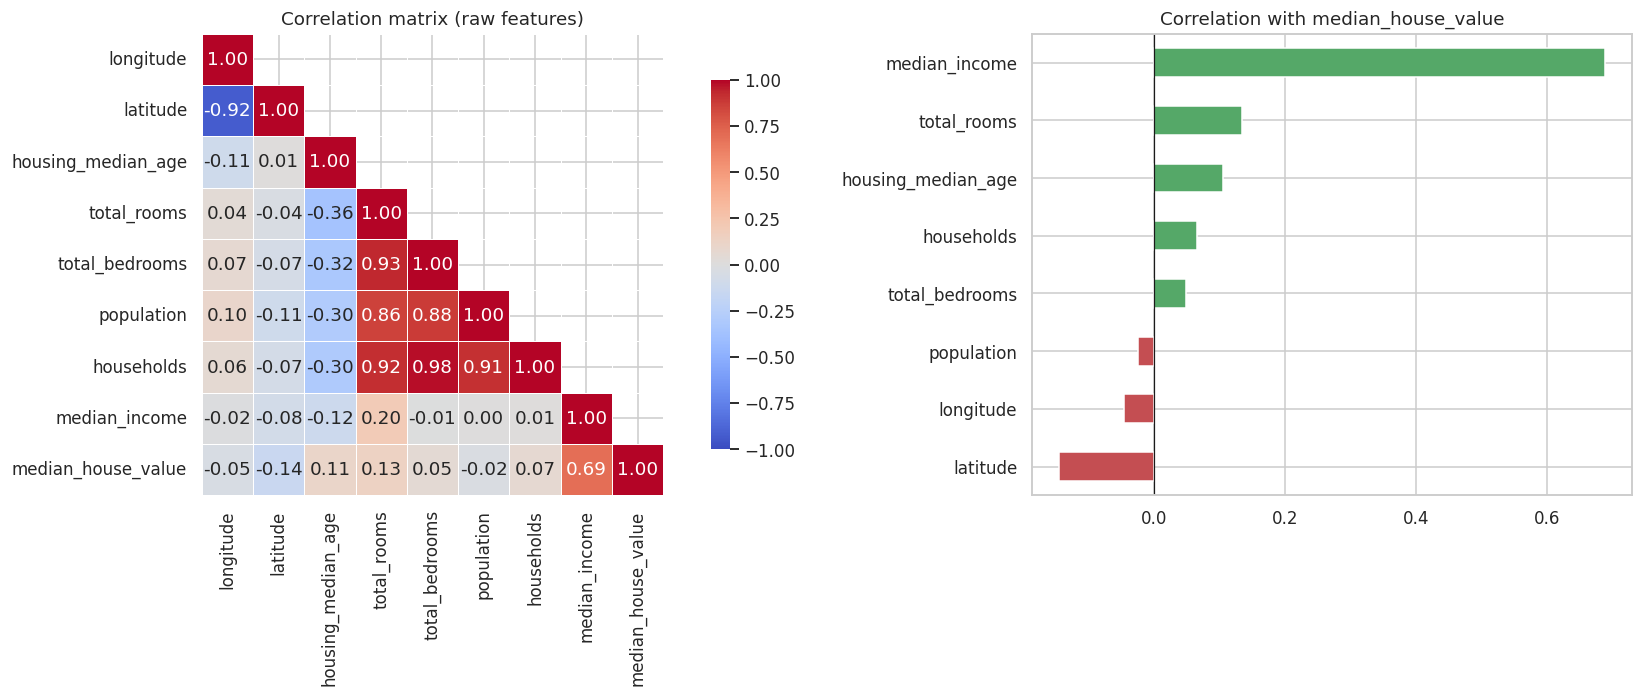

In [5]:
num_cols_all = df.select_dtypes("number").columns.tolist()
corr = df[num_cols_all].corr()

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.6, 1]})
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, linewidths=.5, cbar_kws={"shrink": .8}, ax=axes[0])
axes[0].set_title("Correlation matrix (raw features)")

target_corr = corr["median_house_value"].drop("median_house_value").sort_values()
target_corr.plot.barh(ax=axes[1], color=np.where(target_corr > 0, "C2", "C3"))
axes[1].set_title("Correlation with median_house_value"); axes[1].axvline(0, color="k", lw=.8)
plt.tight_layout(); plt.show()

In [6]:
# strongest feature-feature correlations (collinearity candidates)
pairs = (corr.where(np.tril(np.ones(corr.shape), k=-1).astype(bool)).stack()
             .rename("corr").reset_index().rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
pairs = pairs[(pairs.feature_a != "median_house_value") & (pairs.feature_b != "median_house_value")]
pairs.reindex(pairs["corr"].abs().sort_values(ascending=False).index).head(8).reset_index(drop=True)

,feature_a,feature_b,corr
0,households,total_bedrooms,0.9797
1,total_bedrooms,total_rooms,0.9304
2,latitude,longitude,-0.9247
3,households,total_rooms,0.9185
4,households,population,0.9072
5,population,total_bedrooms,0.8777
6,population,total_rooms,0.8571
7,total_rooms,housing_median_age,-0.3613


**Takeaways**
- `median_income` is by far the strongest single predictor of value (r ≈ 0.69).
- A tight cluster of **count variables** — `total_rooms`, `total_bedrooms`, `population`, `households` — is almost perfectly inter-correlated
  (r ≈ 0.86–0.98). They all measure "how big is this block group", not "how valuable is it". This is classic **multicollinearity**.
- `latitude` and `longitude` are strongly negatively correlated (California's coast runs diagonally), another collinear pair.

In [7]:
skew = df.select_dtypes("number").skew().sort_values(ascending=False)
display(skew.to_frame("skewness").T.style.format("{:.2f}"))

,population,total_rooms,total_bedrooms,households,median_income,median_house_value,latitude,housing_median_age,longitude
skewness,4.94,4.15,3.46,3.41,1.65,0.98,0.47,0.06,-0.30


## 3. Train / test split (80 / 20)

Because income is the dominant predictor, a purely random split could, by bad luck, give the test set a different income mix.
We **stratify on income bins** so both partitions have the same income distribution. The test set is then locked away until Section 8.

In [8]:
df["income_bin"] = pd.cut(df["median_income"], bins=[0, 1.5, 3, 4.5, 6, np.inf], labels=False)

train_df, test_df = train_test_split(df, test_size=0.20, stratify=df["income_bin"], random_state=RANDOM_STATE)

TARGET = "median_house_value"
X_train = train_df.drop(columns=[TARGET, "income_bin"]);  y_train = train_df[TARGET] / SCALE
X_test  = test_df.drop(columns=[TARGET, "income_bin"]);   y_test  = test_df[TARGET] / SCALE

num_cols = [c for c in X_train.columns if c != "ocean_proximity"]
cat_cols = ["ocean_proximity"]
print(f"Train: {X_train.shape}   Test: {X_test.shape}")
display(pd.DataFrame({"train": train_df.income_bin.value_counts(normalize=True).sort_index(),
                      "test":  test_df.income_bin.value_counts(normalize=True).sort_index(),
                      "full":  df.income_bin.value_counts(normalize=True).sort_index()}).style.format("{:.3%}"))

Train: (16512, 9)   Test: (4128, 9)


,train,test,full
income_bin,,,
0,3.979%,3.997%,3.983%
1,31.886%,31.880%,31.885%
2,35.059%,35.053%,35.058%
3,17.630%,17.636%,17.631%
4,11.446%,11.434%,11.444%


## 3.1 Pipeline building blocks

The full pipeline is:

```
impute numeric (median) + one-hot encode category
   → ratio features (rooms/household, bedroom ratio, people/household, log-size)   [raw units]
   → StandardScaler on continuous columns                                           [centres the data]
   → interaction terms (or a full polynomial expansion in the stress test) built from the *standardised* columns
   → StandardScaler again (so every column has equal weight under the L1/L2 penalty)
   → model
```

Building interactions from **standardised (centred)** columns is deliberate: products like `income × age` or `income²` built from
uncentred data are almost perfectly collinear with their parents — centring first removes most of that (demonstrated in Section 5).

In [9]:
class RatioFeatures(BaseEstimator, TransformerMixin):
    """Per-household ratios replace the raw block-group counts.

    log=True  -> ratios that are heavy-tailed (rooms/hh, people/hh) are log-transformed.
    drop_raw  -> drop the four collinear count columns after deriving ratios.
    """
    def __init__(self, log=True, drop_raw=True):
        self.log, self.drop_raw = log, drop_raw
    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]; return self
    def set_output(self, *, transform=None):
        return self
    def transform(self, X):
        X = X.copy()
        rooms_hh = X["total_rooms"] / X["households"]
        pop_hh   = X["population"] / X["households"]
        X["rooms_per_hh"]   = np.log(rooms_hh) if self.log else rooms_hh
        X["pop_per_hh"]     = np.log(pop_hh)   if self.log else pop_hh
        X["bedroom_ratio"]  = X["total_bedrooms"] / X["total_rooms"]
        X["log_households"] = np.log(X["households"])          # keeps a "size of block group" signal
        if self.drop_raw:
            X = X.drop(columns=["total_rooms", "total_bedrooms", "population", "households"])
        return X


class InteractionFeatures(BaseEstimator, TransformerMixin):
    """Interactions / polynomial terms from already-standardised columns."""
    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]; return self
    def set_output(self, *, transform=None):
        return self
    def transform(self, X):
        X = X.copy()
        X["income_x_age"]    = X["median_income"] * X["housing_median_age"]
        X["income_x_rooms"]  = X["median_income"] * X["rooms_per_hh"]
        X["income_sq"]       = X["median_income"] ** 2
        X["lat_sq"]          = X["latitude"] ** 2
        X["lon_sq"]          = X["longitude"] ** 2
        X["lat_x_lon"]       = X["latitude"] * X["longitude"]
        return X


class PolynomialExpansion(BaseEstimator, TransformerMixin):
    """Full polynomial expansion of the (standardised) continuous columns; dummies pass through unchanged."""
    def __init__(self, degree=3):
        self.degree = degree
    def fit(self, X, y=None):
        self.cont_ = [c for c in X.columns if not c.startswith("ocean_proximity_")]
        self.poly_ = PolynomialFeatures(self.degree, include_bias=False).fit(X[self.cont_])
        self.n_features_in_ = X.shape[1]; return self
    def set_output(self, *, transform=None):
        return self
    def transform(self, X):
        P = pd.DataFrame(self.poly_.transform(X[self.cont_]), index=X.index,
                         columns=self.poly_.get_feature_names_out(self.cont_))
        return pd.concat([P, X.drop(columns=self.cont_)], axis=1)


def _continuous(X):
    # standardise everything except the one-hot dummies
    return [c for c in X.columns if not c.startswith("ocean_proximity_")]

def _scaler():
    return ColumnTransformer([("z", StandardScaler(), _continuous)], remainder="passthrough",
                             verbose_feature_names_out=False).set_output(transform="pandas")


MEMORY = tempfile.mkdtemp(prefix="sk_cache_")           # caches fitted pre-processing across GridSearch candidates
DEFAULT_IMPUTER = SimpleImputer(strategy="median")      # revisited (and possibly replaced) in Section 4

def make_pipe(model, imputer=None, engineer=True, log=True, interactions=True, poly_degree=None):
    imputer = clone(DEFAULT_IMPUTER if imputer is None else imputer)
    pre = ColumnTransformer(
        [("num", imputer, num_cols),
         ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat_cols)],
        verbose_feature_names_out=False).set_output(transform="pandas")     # drop="first" avoids the dummy-variable trap
    steps = [("pre", pre)]
    if engineer:
        steps.append(("ratios", RatioFeatures(log=log)))
    steps.append(("scale", _scaler()))
    if poly_degree:
        steps += [("poly", PolynomialExpansion(poly_degree)), ("scale2", _scaler())]
    elif interactions:
        steps += [("interact", InteractionFeatures()), ("scale2", _scaler())]
    steps.append(("model", model))
    return Pipeline(steps, memory=MEMORY)


def metrics(y_true, y_pred):
    """All metrics in DOLLARS (inputs are in $100k units)."""
    return {"RMSE": mean_squared_error(y_true, y_pred) ** .5 * SCALE,
            "MAE":  mean_absolute_error(y_true, y_pred) * SCALE,
            "R²":   r2_score(y_true, y_pred)}

cv5 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_rmse(pipe, X=None, y=None):
    X = X_train if X is None else X; y = y_train if y is None else y
    s = -cross_val_score(pipe, X, y, cv=cv5, scoring="neg_root_mean_squared_error", n_jobs=-1)
    return s.mean() * SCALE, s.std() * SCALE

# smoke test
make_pipe(LinearRegression()).fit(X_train, y_train)[:-1].transform(X_train.head(3)).T

,12655,15502,2908
longitude,-0.9414,1.1718,0.2676
latitude,1.3474,-1.1924,-0.1260
housing_median_age,0.0276,-1.7220,1.2205
median_income,-0.8936,1.2922,-0.5254
rooms_per_hh,0.1943,1.0382,0.1328
pop_per_hh,0.4051,-0.2905,-0.9009
bedroom_ratio,-0.1211,-0.8109,-0.3383
log_households,0.7978,0.9132,-0.3752
income_x_age,0.0825,-2.0123,-0.5045
income_x_rooms,-0.5706,0.6183,-0.4891


## 4. Missing-value imputation

Only `total_bedrooms` is missing (158 training rows). First, is the missingness *informative*?

In [10]:
miss = X_train["total_bedrooms"].isna()
cmp = pd.DataFrame({
    "missing rows": train_df.loc[miss, [TARGET, "median_income", "households", "population"]].mean(),
    "other rows":   train_df.loc[~miss, [TARGET, "median_income", "households", "population"]].mean()})
print(f"Missing in training set: {miss.sum()} rows ({miss.mean():.2%})")
display(cmp)

Missing in training set: 158 rows (0.96%)


,missing rows,other rows
median_house_value,"199,067.1203","207,082.0153"
median_income,3.7340,3.8773
households,503.3861,496.9502
population,"1,485.2025","1,419.0544"


The rows with missing bedrooms look broadly like everyone else (slightly lower value/income, but nothing dramatic), consistent with
missing-at-random. We compare four imputers, always fitted **inside the CV folds**, using OLS on the full engineered pipeline.
Because every imputer is scored on the *same* 5 folds, the right comparison is **paired** (fold by fold), not a comparison of overlapping standard deviations.

In [11]:
imputers = {
    "Median": SimpleImputer(strategy="median"),
    "Mean": SimpleImputer(strategy="mean"),
    "KNN (k=5)": KNNImputer(n_neighbors=5),
    "Iterative (BayesianRidge)": IterativeImputer(random_state=RANDOM_STATE, max_iter=10),
}
def cv_folds(pipe, X=None, y=None):
    X = X_train if X is None else X; y = y_train if y is None else y
    return -cross_val_score(pipe, X, y, cv=cv5, scoring="neg_root_mean_squared_error") * SCALE

folds = pd.DataFrame({n: cv_folds(make_pipe(LinearRegression(), imputer=imp)) for n, imp in imputers.items()}).T
folds.columns = [f"fold {i+1}" for i in range(folds.shape[1])]
paired = folds.sub(folds.loc["Median"], axis=1)
imp_df = pd.DataFrame({
    "mean CV RMSE ($)": folds.mean(axis=1),
    "Δ vs median ($)": paired.mean(axis=1),
    "SE of Δ ($)": paired.std(axis=1, ddof=1) / np.sqrt(folds.shape[1]),
    "folds better than median": (paired < 0).sum(axis=1),
})
display(folds.style.format("{:,.0f}").set_caption("RMSE ($) per CV fold"))
display(imp_df.style.format({"mean CV RMSE ($)": "{:,.0f}", "Δ vs median ($)": "{:+,.0f}", "SE of Δ ($)": "{:,.0f}", "folds better than median": "{:.0f}/5"}))

,fold 1,fold 2,fold 3,fold 4,fold 5
Median,"63,620","65,819","67,891","66,338","65,493"
Mean,"63,754","65,936","67,930","66,476","65,636"
KNN (k=5),"63,398","65,445","65,968","65,520","65,003"
Iterative (BayesianRidge),"63,423","65,416","65,778","65,481","65,002"


,mean CV RMSE ($),Δ vs median ($),SE of Δ ($),folds better than median
Median,"65,832",+0,0,0/5
Mean,"65,946",+114,19,0/5
KNN (k=5),"65,067",-765,305,5/5
Iterative (BayesianRidge),"65,020",-812,342,5/5


Imputation is **not** negligible here: KNN and iterative imputation beat the median in every fold. Why would filling 1 % of one column matter? Because `total_bedrooms`
feeds the engineered `bedroom_ratio = bedrooms / rooms`. A median bedroom count paired with an unrelated room count gives an implausible ratio. Let's check that mechanism directly:

In [12]:
obs_ratio = (X_train.loc[~miss, "total_bedrooms"] / X_train.loc[~miss, "total_rooms"])
lo, hi = obs_ratio.quantile([.01, .99])
rows = [{"Source": "Observed rows (ground truth)", "mean ratio": obs_ratio.mean(), "std": obs_ratio.std(), "% outside observed 1–99th pct": 2.0}]
for name, imp in imputers.items():
    Xi = pd.DataFrame(clone(imp).fit_transform(X_train[num_cols]), columns=num_cols, index=X_train.index)
    r = (Xi["total_bedrooms"] / Xi["total_rooms"])[miss]
    rows.append({"Source": f"Imputed rows – {name}", "mean ratio": r.mean(), "std": r.std(),
                 "% outside observed 1–99th pct": 100 * ((r < lo) | (r > hi)).mean()})
display(pd.DataFrame(rows).set_index("Source").style.format({"mean ratio": "{:.3f}", "std": "{:.3f}", "% outside observed 1–99th pct": "{:.0f}%"}))

,mean ratio,std,% outside observed 1–99th pct
Source,,,
Observed rows (ground truth),0.213,0.057,2%
Imputed rows – Median,0.299,0.314,40%
Imputed rows – Mean,0.370,0.388,40%
Imputed rows – KNN (k=5),0.218,0.052,1%
Imputed rows – Iterative (BayesianRidge),0.220,0.085,4%


Median/mean imputation produce bedroom ratios far more dispersed than reality (many outside the plausible range), whereas neighbour- and regression-based imputers keep the ratio realistic
because they exploit the correlated `total_rooms`, `households`, `population`.

**Decision:** we use **KNN imputation (k = 5)** from here on. It is statistically tied with the iterative imputer (≈ $50 apart), but simpler, faster and deterministic.
The imputer is part of every pipeline, so it is re-fitted on training folds only — no leakage.

In [13]:
DEFAULT_IMPUTER = KNNImputer(n_neighbors=5)   # make_pipe() picks this up from now on

## 5. Multicollinearity: diagnose first, then treat

**Variance Inflation Factor** for feature *j*: `VIF_j = 1 / (1 − R²_j)`, where `R²_j` comes from regressing feature *j* on all the others.
Rules of thumb: VIF > 5 is worrying, > 10 is severe. VIF equals the diagonal of the inverse correlation matrix, so we can compute it with NumPy.
We also report the **condition number** of the standardised design matrix (large ⇒ ill-conditioned normal equations ⇒ unstable OLS coefficients).

In [14]:
def vif(frame):
    R = np.corrcoef(frame.values, rowvar=False)
    return pd.Series(np.diag(np.linalg.inv(R)), index=frame.columns, name="VIF")

def cond_number(frame):
    Z = (frame - frame.mean()) / frame.std(ddof=0)
    return np.linalg.cond(Z.values)

views = {
    "A. raw counts":                       make_pipe(LinearRegression(), engineer=False, interactions=False),
    "B. + ratios (counts dropped)":        make_pipe(LinearRegression(), engineer=True,  interactions=False),
    "C. + interactions (centred)":         make_pipe(LinearRegression(), engineer=True,  interactions=True),
    "D. degree-3 polynomial expansion":    make_pipe(LinearRegression(), engineer=True,  poly_degree=3),
}
frames = {k: p.fit(X_train, y_train)[:-1].transform(X_train) for k, p in views.items()}
dummies = lambda f: [c for c in f.columns if c.startswith("ocean_proximity_")]

summary, vif_tables = [], {}
for k, f in frames.items():
    cont = f.drop(columns=dummies(f))
    v = vif(cont); vif_tables[k] = v
    summary.append({"Feature set": k, "# continuous features": cont.shape[1], "max VIF": v.max(),
                    "# VIF > 10": int((v > 10).sum()), "median VIF": v.median(), "condition number": cond_number(cont)})
display(pd.DataFrame(summary).set_index("Feature set").style.format(
    {"max VIF": "{:,.1f}", "median VIF": "{:,.1f}", "condition number": "{:,.1f}"}))

,# continuous features,max VIF,# VIF > 10,median VIF,condition number
Feature set,,,,,
A. raw counts,8,36.1,3,8.8,16.2
B. + ratios (counts dropped),8,9.7,0,2.6,6.8
C. + interactions (centred),14,37.6,5,3.7,15.4
D. degree-3 polynomial expansion,164,"1,371.7",141,44.7,229.6


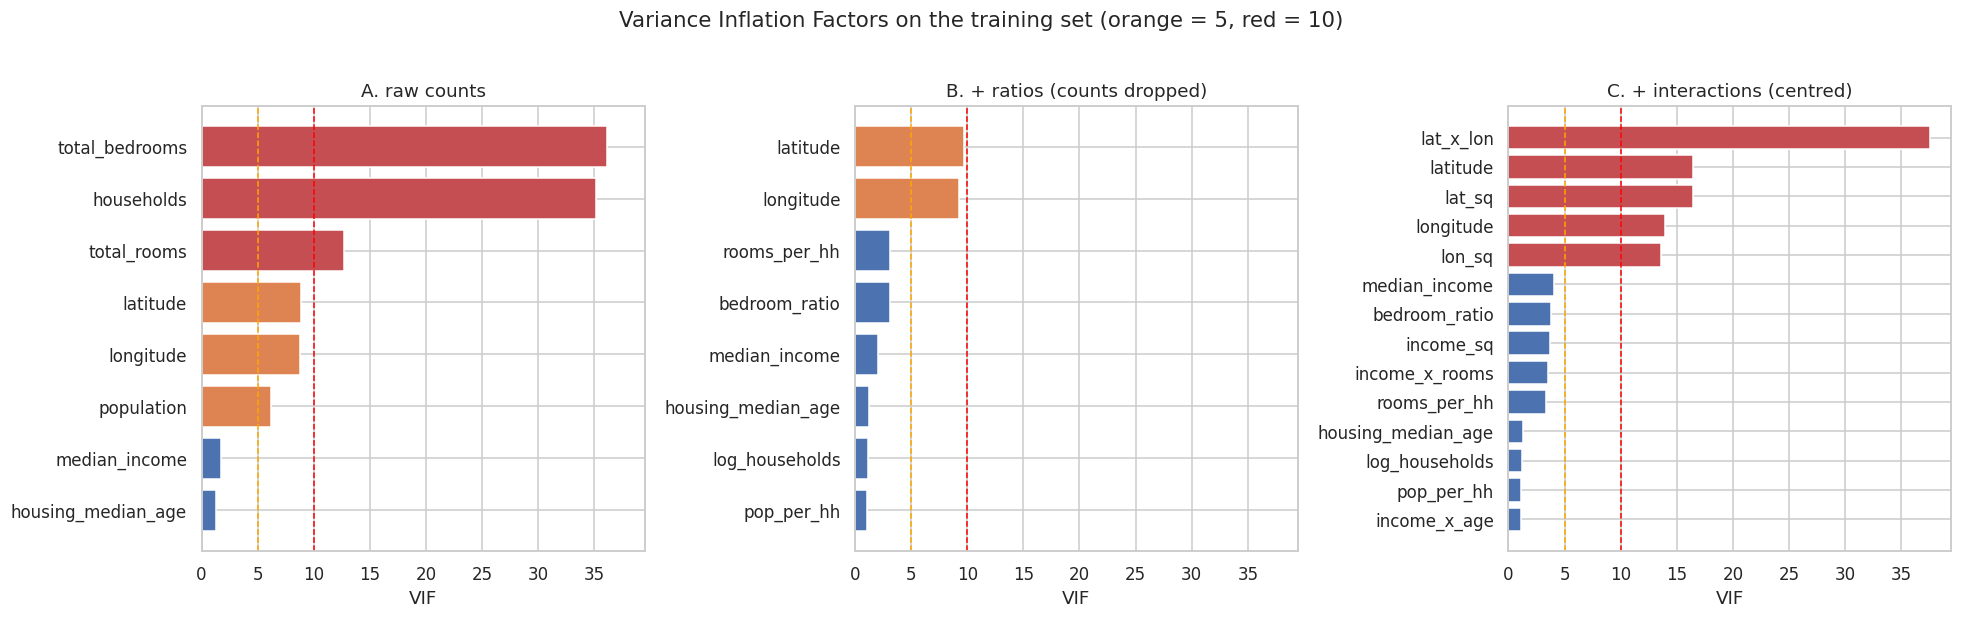

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharex=True)
for ax, k in zip(axes, list(vif_tables)[:3]):
    v = vif_tables[k].sort_values()
    ax.barh(v.index, v.values, color=np.where(v > 10, "C3", np.where(v > 5, "C1", "C0")))
    ax.axvline(5, color="orange", ls="--", lw=1); ax.axvline(10, color="red", ls="--", lw=1)
    ax.set_title(k); ax.set_xlabel("VIF")
plt.suptitle("Variance Inflation Factors on the training set (orange = 5, red = 10)", y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

corr(income, income²)     uncentred: 0.941 | VIF = 8.8
corr(income_z, income_z²)   centred: 0.628 | VIF = 1.7


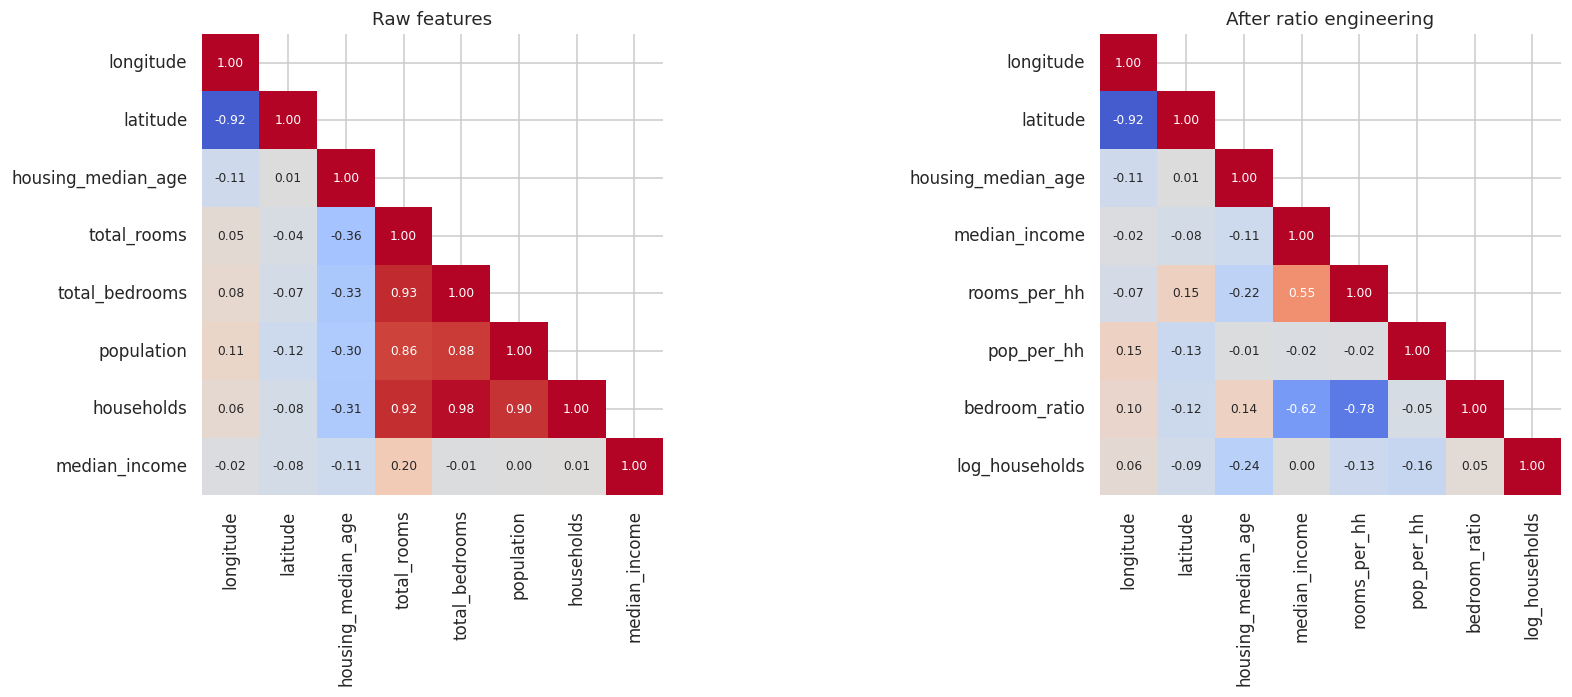

In [16]:
# Why centre before building interactions?  income vs income² with and without centring
inc = X_train["median_income"]
unc = pd.DataFrame({"income": inc, "income_sq": inc ** 2})
z = (inc - inc.mean()) / inc.std()
cen = pd.DataFrame({"income_z": z, "income_z_sq": z ** 2})
print("corr(income, income²)     uncentred:", round(unc.corr().iloc[0, 1], 3), "| VIF =", round(vif(unc).iloc[0], 1))
print("corr(income_z, income_z²)   centred:", round(cen.corr().iloc[0, 1], 3), "| VIF =", round(vif(cen).iloc[0], 1))

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, key, title in [(axes[0], "A. raw counts", "Raw features"), (axes[1], "B. + ratios (counts dropped)", "After ratio engineering")]:
    f = frames[key].drop(columns=dummies(frames[key]))
    c = f.corr()
    sns.heatmap(c, mask=np.triu(np.ones_like(c, dtype=bool), k=1), annot=True, fmt=".2f", cmap="coolwarm",
                center=0, vmin=-1, vmax=1, square=True, cbar=False, ax=ax, annot_kws={"size": 8})
    ax.set_title(title)
plt.tight_layout(); plt.show()

**What the diagnostics say**

| Feature set | Verdict |
|---|---|
| **A. raw counts** | The classic cluster: `total_bedrooms` (VIF ≈ 36), `households` (≈ 35) and `total_rooms` (≈ 13) are all above 10. They measure the same thing: "how big is this block group". |
| **B. + ratios** | Replacing the counts by per-household ratios plus one size proxy fixes it: max VIF ≈ 9.7 (only `latitude`/`longitude` remain elevated), none above 10, condition number falls from ≈ 16 to ≈ 7. |
| **C. + interactions** | The lat/lon polynomial terms (`lat_x_lon`, `lat_sq`, `lon_sq`, plus latitude and longitude themselves) bring five features back above 10 (max ≈ 38). This is unavoidable when a linear model gets curvature in coordinates, and the terms are spatially meaningful, so we keep them. |
| **D. degree-3 polynomial** | Genuine, severe multicollinearity: max VIF ≈ 1,370, 141 of 164 features above 10, condition number ≈ 230. This is the regime Ridge and Lasso exist for (Section 8). |

Two caveats. First, even the worst case has a modest condition number, so OLS is numerically stable here: the cost of collinearity is *variance* (unstable coefficients and over-fitting), not a failed matrix inversion.
Second, centring matters: `income` vs `income²` has VIF 8.8 uncentred but 1.7 once centred.

**Treatments applied**

1. **Replace the four collinear counts with per-household ratios** (`rooms_per_hh`, `pop_per_hh`, `bedroom_ratio`) plus `log_households` as a single "size" proxy.
2. **Centre before creating polynomial/interaction terms**, avoiding the "income vs income²" trap above.
3. **Leave the remaining lat/lon collinearity to Ridge and Lasso.** Latitude and longitude are spatially meaningful, so deleting them would be the wrong fix.
4. **Drop one dummy level** (`drop="first"`) so the one-hot block is not perfectly collinear with the intercept.

## 6. Feature-engineering ablation (decided by cross-validation, not the test set)

Each row adds one idea to an OLS model (KNN imputation throughout). Selecting features by CV on the *training* set keeps the test set clean for the final verdict.

,CV RMSE ($),± std ($),worst fold ($)
Pipeline,,,
1. Raw features (impute + scale + one-hot),"69,135","1,291","70,944"
2. + ratio features (not log-transformed),"78,066","16,475","107,510"
3. + log-transform heavy-tailed ratios,"66,474","1,106","67,459"
4. + centred interactions & polynomials,"65,067",994,"65,968"


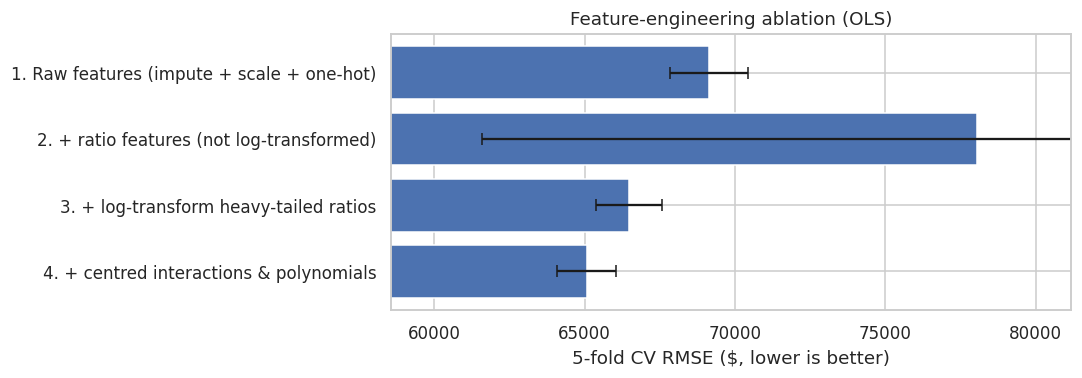

In [17]:
ablation = {
    "1. Raw features (impute + scale + one-hot)":      dict(engineer=False, interactions=False),
    "2. + ratio features (not log-transformed)":       dict(engineer=True,  log=False, interactions=False),
    "3. + log-transform heavy-tailed ratios":          dict(engineer=True,  log=True,  interactions=False),
    "4. + centred interactions & polynomials":         dict(engineer=True,  log=True,  interactions=True),
}
abl_rows = []
for name, kw in ablation.items():
    f = cv_folds(make_pipe(LinearRegression(), **kw))
    abl_rows.append({"Pipeline": name, "CV RMSE ($)": f.mean(), "± std ($)": f.std(ddof=1), "worst fold ($)": f.max()})
abl = pd.DataFrame(abl_rows).set_index("Pipeline")
display(abl.style.format("{:,.0f}"))

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.barh(abl.index[::-1], abl["CV RMSE ($)"][::-1], xerr=abl["± std ($)"][::-1], color="C0", capsize=4)
ax.set_xlim(abl["CV RMSE ($)"].min() * .9, abl["CV RMSE ($)"].max() * 1.04); ax.set_xlabel("5-fold CV RMSE ($, lower is better)")
ax.set_title("Feature-engineering ablation (OLS)")
plt.tight_layout(); plt.show()

**Reading the ablation** (5-fold CV RMSE on the training set)

- **Naïve ratios hurt badly:** $69.1k → $78.1k, and the fold-to-fold spread explodes (± $16k, worst fold $107k). A few block groups have absurd ratios (well over 100 rooms per household), and an untransformed linear term is dominated by them.
- **Log-transforming the ratios repairs that** and beats the raw baseline ($66.5k).
- **Centred interactions and lat/lon polynomials give a further gain** to $65.1k, mainly because the squared and product terms let the "price plane" curve toward the coast.

Total improvement over the raw baseline is about $4k (≈ 6 %). We carry the full pipeline (row 4) forward as the **18-feature pipeline**.

## 7. OLS, Ridge and Lasso with `GridSearchCV` — the 18-feature pipeline

- **OLS** minimises squared error — no penalty, no hyper-parameter.
- **Ridge (L2)** adds `α‖w‖₂²`: shrinks coefficients smoothly, stabilising collinear groups.
- **Lasso (L1)** adds `α‖w‖₁`: can shrink coefficients to *exactly* zero, performing feature selection.

All three are assessed with the same 5-fold CV on the training set (`scoring = neg RMSE`). The α grids are wide and log-spaced. Lasso's α depends on the target's
units, so its range differs from Ridge's (the target is in $100k).

In [18]:
ridge_grid = {"model__alpha": np.logspace(-3, 4, 29)}
lasso_grid = {"model__alpha": np.logspace(-7, -0.5, 31)}
kw = dict(cv=cv5, scoring="neg_root_mean_squared_error", return_train_score=True)

gs_ridge = GridSearchCV(make_pipe(Ridge()), ridge_grid, **kw).fit(X_train, y_train)
gs_lasso = GridSearchCV(make_pipe(Lasso(max_iter=100_000, tol=1e-5)), lasso_grid, **kw).fit(X_train, y_train)
ols = make_pipe(LinearRegression()).fit(X_train, y_train)

print(f"Ridge best α = {gs_ridge.best_params_['model__alpha']:.4g}   CV RMSE = ${-gs_ridge.best_score_*SCALE:,.0f}")
print(f"Lasso best α = {gs_lasso.best_params_['model__alpha']:.4g}   CV RMSE = ${-gs_lasso.best_score_*SCALE:,.0f}")

Ridge best α = 1   CV RMSE = $65,067
Lasso best α = 1.995e-06   CV RMSE = $65,067


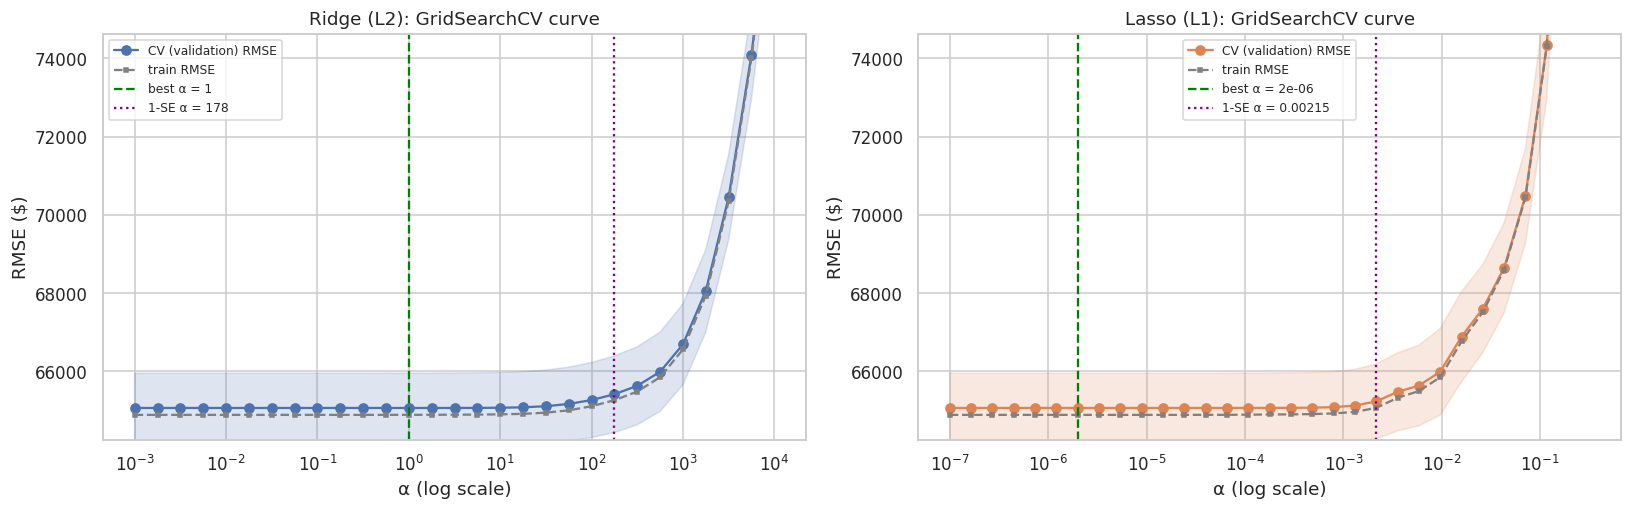

In [19]:
def one_se_alpha(gs, name="model__alpha"):
    """Largest alpha whose CV score is within 1 standard error of the best (the 'parsimonious' choice)."""
    r = gs.cv_results_
    alphas = np.array([p[name] for p in r["params"]])
    mean, std = -r["mean_test_score"], r["std_test_score"]
    best = mean.argmin()
    se = std[best] / np.sqrt(gs.cv.get_n_splits())
    return alphas[mean <= mean[best] + se].max()

def plot_cv_curve(gs, ax, title, color):
    r = gs.cv_results_
    a = np.array([p["model__alpha"] for p in r["params"]])
    val, val_sd, trn = -r["mean_test_score"] * SCALE, r["std_test_score"] * SCALE, -r["mean_train_score"] * SCALE
    ax.plot(a, val, "o-", color=color, label="CV (validation) RMSE")
    ax.fill_between(a, val - val_sd, val + val_sd, color=color, alpha=.18)
    ax.plot(a, trn, "s--", color="gray", ms=3, label="train RMSE")
    ax.axvline(gs.best_params_["model__alpha"], color="green", ls="--", label=f"best α = {gs.best_params_['model__alpha']:.3g}")
    ax.axvline(one_se_alpha(gs), color="purple", ls=":", label=f"1-SE α = {one_se_alpha(gs):.3g}")
    ax.set_xscale("log"); ax.set_xlabel("α (log scale)"); ax.set_ylabel("RMSE ($)")
    ax.set_title(title); ax.legend(fontsize=8)
    lo = min(val.min(), trn.min()); ax.set_ylim(lo * .99, lo * 1.15)      # y-axis zoomed: very small α can be far above the top edge

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
plot_cv_curve(gs_ridge, axes[0], "Ridge (L2): GridSearchCV curve", "C0")
plot_cv_curve(gs_lasso, axes[1], "Lasso (L1): GridSearchCV curve", "C1")
plt.tight_layout(); plt.show()

**What the curves show.** The Ridge CV curve is essentially flat until α is large, and the Lasso optimum sits at a *tiny* α (≈ 2·10⁻⁶), i.e. almost no penalty. All three models reach the same CV RMSE (≈ $65.1k).
With ~16,500 training rows and 18 well-conditioned features there is little variance for regularisation to remove, so the best penalty is close to zero and OLS is already near-optimal.
The "1-SE" α (purple) is the strongest penalty still statistically tied with the best; it matters in Section 10.1.

The paths below show *how* each penalty acts as α grows. Ridge shrinks every coefficient smoothly toward zero without reaching it. Lasso drives coefficients to **exactly** zero one after another, which is what makes it a feature-selection method.

### 7.1 Regularisation paths: how do the coefficients behave as α grows?

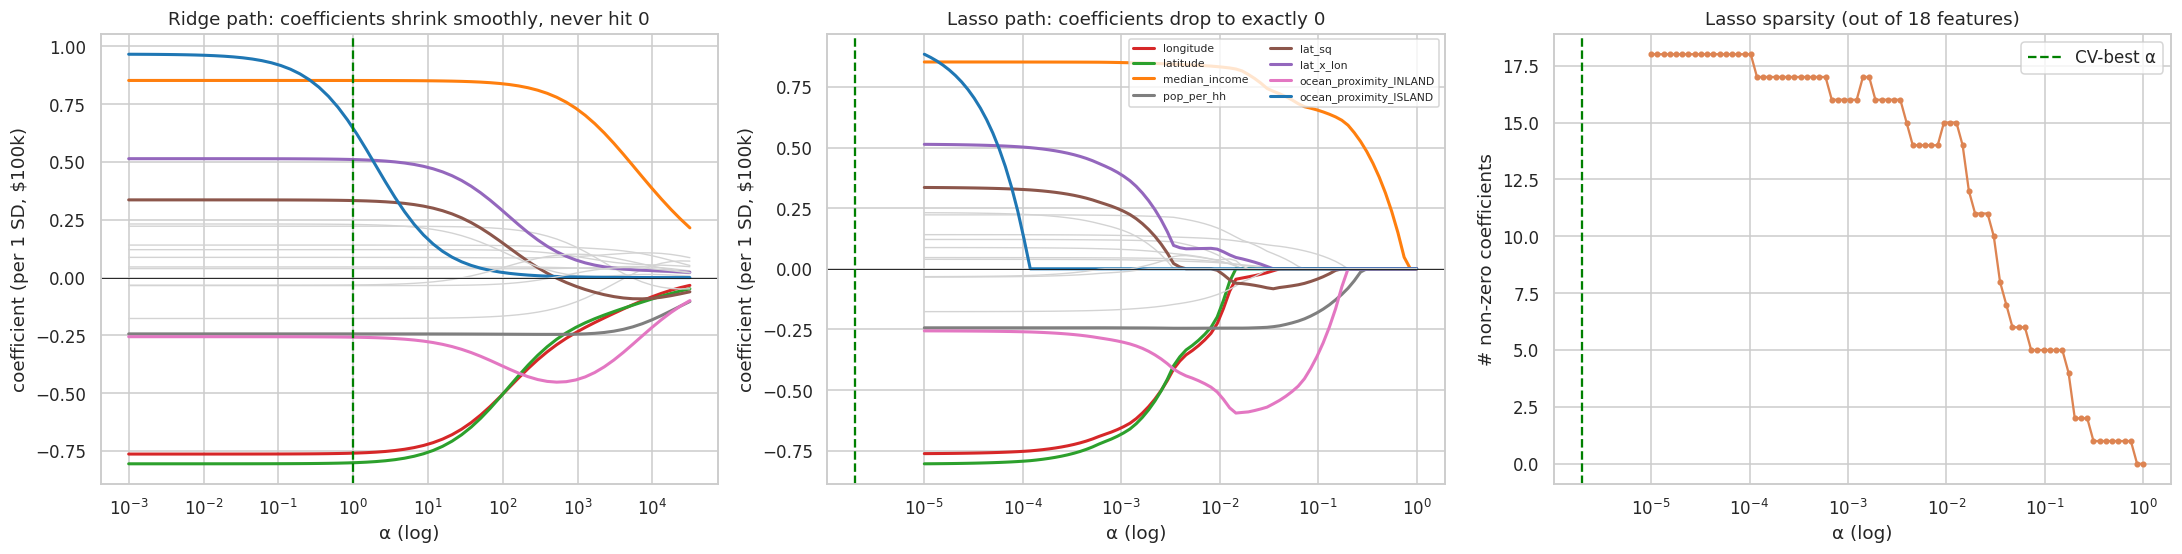

In [20]:
Z_train = ols[:-1].transform(X_train)               # fully pre-processed training matrix
feat = Z_train.columns.tolist()

r_alphas = np.logspace(-3, 4.5, 60)
ridge_path = np.array([Ridge(alpha=a).fit(Z_train, y_train).coef_ for a in r_alphas])
# lasso_path has no intercept, so centre X and y first (otherwise the un-centred dummies distort the path)
l_alphas, l_coefs, _ = lasso_path((Z_train - Z_train.mean()).values, (y_train - y_train.mean()).values, alphas=np.logspace(-5, 0, 80))

top = np.argsort(-np.abs(LinearRegression().fit(Z_train, y_train).coef_))[:8]
cmap = plt.cm.tab10

fig, axes = plt.subplots(1, 3, figsize=(20, 5.2))
for j in range(len(feat)):
    kw_ = dict(color=cmap(list(top).index(j) % 10), lw=2, label=feat[j]) if j in top else dict(color="lightgray", lw=.9)
    axes[0].plot(r_alphas, ridge_path[:, j], **kw_)
    axes[1].plot(l_alphas, l_coefs[j], **kw_)
axes[0].set_xscale("log"); axes[0].set_title("Ridge path: coefficients shrink smoothly, never hit 0")
axes[1].set_xscale("log"); axes[1].set_title("Lasso path: coefficients drop to exactly 0")
for ax in axes[:2]:
    ax.set_xlabel("α (log)"); ax.set_ylabel("coefficient (per 1 SD, $100k)"); ax.axhline(0, color="k", lw=.6)
axes[0].axvline(gs_ridge.best_params_["model__alpha"], color="green", ls="--")
axes[1].axvline(gs_lasso.best_params_["model__alpha"], color="green", ls="--")
axes[1].legend(fontsize=7, loc="upper right", ncol=2)

n_nonzero = (l_coefs != 0).sum(axis=0)
axes[2].plot(l_alphas, n_nonzero, "o-", color="C1", ms=3)
axes[2].axvline(gs_lasso.best_params_["model__alpha"], color="green", ls="--", label="CV-best α")
axes[2].set_xscale("log"); axes[2].set_xlabel("α (log)"); axes[2].set_ylabel("# non-zero coefficients"); axes[2].legend()
axes[2].set_title(f"Lasso sparsity (out of {len(feat)} features)")
plt.tight_layout(); plt.show()

## 8. Stress test: where multicollinearity really bites — degree-3 polynomial expansion

With 18 well-behaved features OLS is already stable (see the condition numbers in Section 5). To see what Ridge and Lasso are *for*, we give the models a much richer, much more collinear
feature space: **every polynomial term up to degree 3** of the 8 standardised continuous features (164 terms) plus the 4 dummies = **168 features**. This lets the models bend
the price surface freely over latitude/longitude — but the terms are heavily correlated (Section 5, row D), so unpenalised OLS should struggle.

In [21]:
ridge_grid_B = {"model__alpha": np.logspace(-1, 4, 21)}
lasso_grid_B = {"model__alpha": np.logspace(-4.5, -1.5, 16)}

gs_ridge_B = GridSearchCV(make_pipe(Ridge(), poly_degree=3), ridge_grid_B, **kw).fit(X_train, y_train)
gs_lasso_B = GridSearchCV(make_pipe(Lasso(max_iter=50_000, tol=1e-4), poly_degree=3), lasso_grid_B, **kw).fit(X_train, y_train)
ols_B = make_pipe(LinearRegression(), poly_degree=3).fit(X_train, y_train)

print(f"OLS   (168 features)  CV RMSE = ${cv_folds(make_pipe(LinearRegression(), poly_degree=3)).mean():,.0f}")
print(f"Ridge best α = {gs_ridge_B.best_params_['model__alpha']:.4g}   CV RMSE = ${-gs_ridge_B.best_score_*SCALE:,.0f}")
print(f"Lasso best α = {gs_lasso_B.best_params_['model__alpha']:.4g}   CV RMSE = ${-gs_lasso_B.best_score_*SCALE:,.0f}")

OLS   (168 features)  CV RMSE = $67,906
Ridge best α = 316.2   CV RMSE = $62,250
Lasso best α = 0.003162   CV RMSE = $60,104


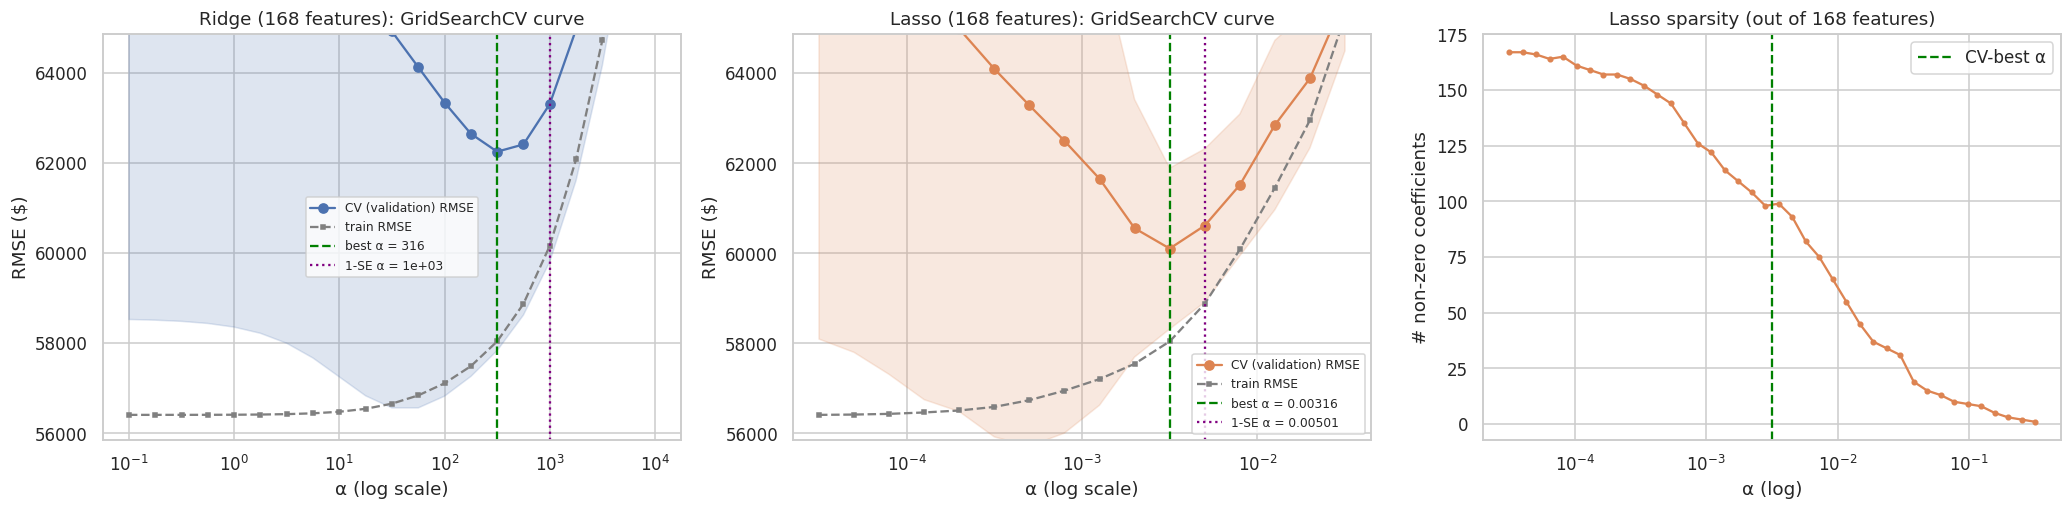

In [22]:
Z_B = ols_B[:-1].transform(X_train)
l_alphas_B, l_coefs_B, _ = lasso_path((Z_B - Z_B.mean()).values, (y_train - y_train.mean()).values,
                                      alphas=np.logspace(-4.5, -0.5, 40), tol=1e-4, max_iter=50_000)

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
plot_cv_curve(gs_ridge_B, axes[0], "Ridge (168 features): GridSearchCV curve", "C0")
plot_cv_curve(gs_lasso_B, axes[1], "Lasso (168 features): GridSearchCV curve", "C1")
axes[2].plot(l_alphas_B, (l_coefs_B != 0).sum(axis=0), "o-", color="C1", ms=3)
axes[2].axvline(gs_lasso_B.best_params_["model__alpha"], color="green", ls="--", label="CV-best α")
axes[2].set_xscale("log"); axes[2].set_xlabel("α (log)"); axes[2].set_ylabel("# non-zero coefficients"); axes[2].legend()
axes[2].set_title(f"Lasso sparsity (out of {Z_B.shape[1]} features)")
plt.tight_layout(); plt.show()

**This is where the models separate.**

- **OLS on 168 features over-fits**: CV RMSE $67.9k (worse than the 18-feature model's $65.1k), with a clear gap between training error (≈ $56.4k at tiny α) and validation error.
  The validation bands at small α are huge: in some folds a few extreme predictions dominate the error. (The plot is zoomed in; at the left edge the CV RMSE is far above the top of the axis.)
- **Ridge** (best α ≈ 316) cuts CV RMSE to $62.3k by shrinking the correlated polynomial terms.
- **Lasso** (best α ≈ 0.003) does better still, $60.1k, while discarding about 40 % of the features (97 of 168 survive; see Section 10.1).

Compared with the 18-feature models, the richer feature space is worth having only **because** it is regularised: unpenalised, the extra flexibility costs more in variance than it gains in bias.

## 9. Test-set benchmark

We now touch the test set **once** to score all six tuned models (three on the 18-feature pipeline, three on the 168-feature polynomial pipeline).
For context we also show CV and training error, which reveal the over-fitting gap.

,Test RMSE ($),Test MAE ($),Test R²,CV RMSE ($),Train RMSE ($),Train R²
Model,,,,,,
OLS (18 feat.),"64,447","46,569",0.6813,"65,067","64,910",0.6852
Ridge (18 feat.),"64,463","46,578",0.6812,"65,067","64,911",0.6852
Lasso (18 feat.),"64,448","46,569",0.6813,"65,067","64,910",0.6852
OLS (168 feat.),"65,562","41,117",0.6702,"67,906","56,621",0.7605
Ridge (168 feat.),"58,871","41,684",0.7341,"62,250","57,976",0.7489
Lasso (168 feat.),"58,089","41,392",0.7411,"60,104","58,167",0.7472



Best model by CV RMSE (selection never used the test set): Lasso (168 feat.)


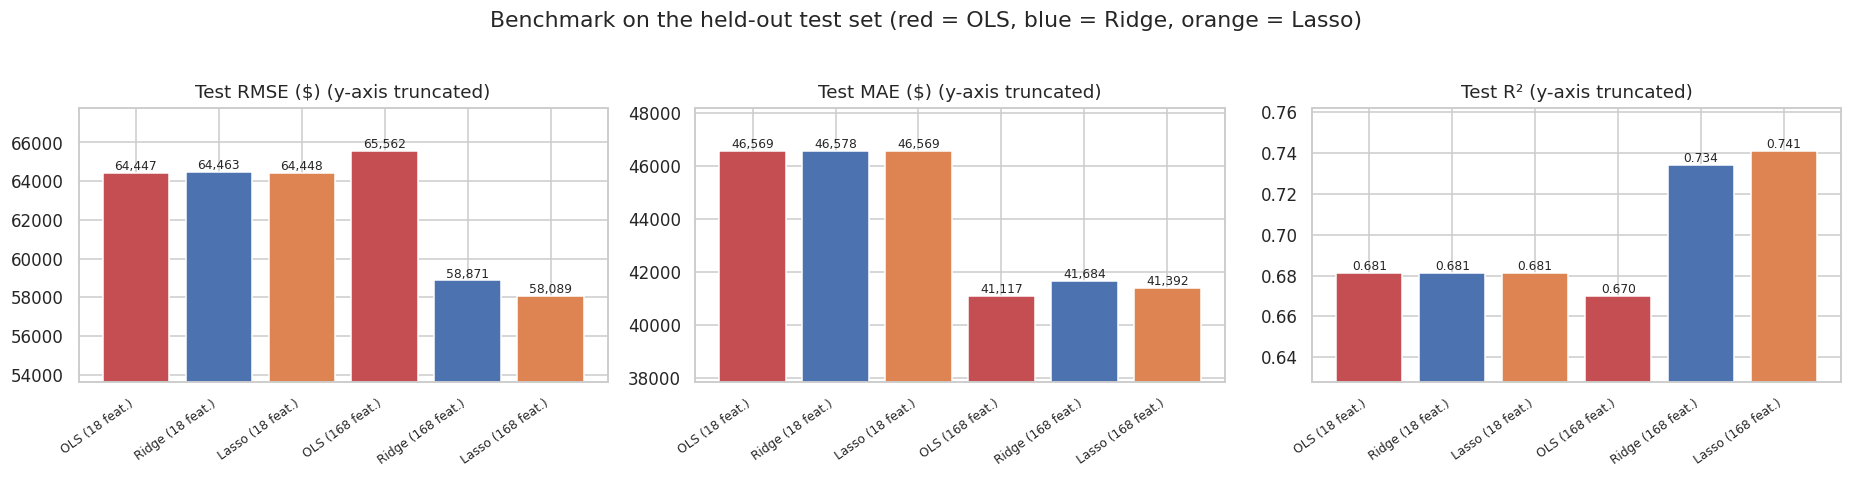

In [23]:
final_models = {
    "OLS (18 feat.)":   ols,                         "Ridge (18 feat.)":  gs_ridge.best_estimator_,   "Lasso (18 feat.)":  gs_lasso.best_estimator_,
    "OLS (168 feat.)":  ols_B,                       "Ridge (168 feat.)": gs_ridge_B.best_estimator_, "Lasso (168 feat.)": gs_lasso_B.best_estimator_,
}
cv_means = {
    "OLS (18 feat.)":   cv_folds(make_pipe(LinearRegression())).mean(),
    "Ridge (18 feat.)": -gs_ridge.best_score_ * SCALE,   "Lasso (18 feat.)": -gs_lasso.best_score_ * SCALE,
    "OLS (168 feat.)":  cv_folds(make_pipe(LinearRegression(), poly_degree=3)).mean(),
    "Ridge (168 feat.)": -gs_ridge_B.best_score_ * SCALE, "Lasso (168 feat.)": -gs_lasso_B.best_score_ * SCALE,
}
test_pred  = {k: m.predict(X_test) for k, m in final_models.items()}
train_pred = {k: m.predict(X_train) for k, m in final_models.items()}

rows = []
for k in final_models:
    t, tr = metrics(y_test, test_pred[k]), metrics(y_train, train_pred[k])
    rows.append({"Model": k, "Test RMSE ($)": t["RMSE"], "Test MAE ($)": t["MAE"], "Test R²": t["R²"],
                 "CV RMSE ($)": cv_means[k], "Train RMSE ($)": tr["RMSE"], "Train R²": tr["R²"]})
bench = pd.DataFrame(rows).set_index("Model")
display(bench.style.format({"Test RMSE ($)": "{:,.0f}", "Test MAE ($)": "{:,.0f}", "Test R²": "{:.4f}",
                            "CV RMSE ($)": "{:,.0f}", "Train RMSE ($)": "{:,.0f}", "Train R²": "{:.4f}"})
        .background_gradient(subset=["Test RMSE ($)", "Test MAE ($)"], cmap="Greens_r"))

best_name = bench["CV RMSE ($)"].idxmin()
print(f"\nBest model by CV RMSE (selection never used the test set): {best_name}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, col, lab in zip(axes, ["Test RMSE ($)", "Test MAE ($)", "Test R²"], ["RMSE ($)", "MAE ($)", "R²"]):
    colors = ["C3", "C0", "C1"] * 2
    ax.bar(range(6), bench[col], color=colors)
    ax.set_xticks(range(6)); ax.set_xticklabels(bench.index, rotation=35, ha="right", fontsize=8)
    lo, hi = bench[col].min(), bench[col].max(); pad = (hi - lo) * .6
    ax.set_ylim(lo - pad, hi + pad * .5); ax.set_title(f"Test {lab} (y-axis truncated)")
    for i, v in enumerate(bench[col]): ax.text(i, v, f"{v:,.0f}" if col != "Test R²" else f"{v:.3f}", ha="center", va="bottom", fontsize=8)
plt.suptitle("Benchmark on the held-out test set (red = OLS, blue = Ridge, orange = Lasso)", y=1.03)
plt.tight_layout(); plt.show()

### 9.1 Is any difference real? Paired bootstrap on the test set

Point estimates this close can be noise. We bootstrap the 4,128 test rows (2,000 resamples) and compute the **paired** RMSE difference for the comparisons that matter.

,RMSE,95% CI low,95% CI high
OLS (18 feat.),"64,447","62,253","66,682"
Ridge (18 feat.),"64,463","62,252","66,697"
Lasso (18 feat.),"64,448","62,252","66,682"
OLS (168 feat.),"65,562","56,715","77,487"
Ridge (168 feat.),"58,871","56,615","61,199"
Lasso (168 feat.),"58,089","56,085","60,050"


,mean Δ RMSE ($),95% CI low,95% CI high,A better in % of resamples
Comparison (A − B),,,,
Ridge (18 feat.) − OLS (18 feat.),+16,-22,+63,26.1%
Lasso (18 feat.) − OLS (18 feat.),+0,-1,+3,35.0%
Ridge (168 feat.) − OLS (168 feat.),"-6,547","-18,444",+978,90.4%
Lasso (168 feat.) − OLS (168 feat.),"-7,308","-18,875",+713,93.1%
Lasso (168 feat.) − Lasso (18 feat.),"-6,379","-7,722","-5,173",100.0%


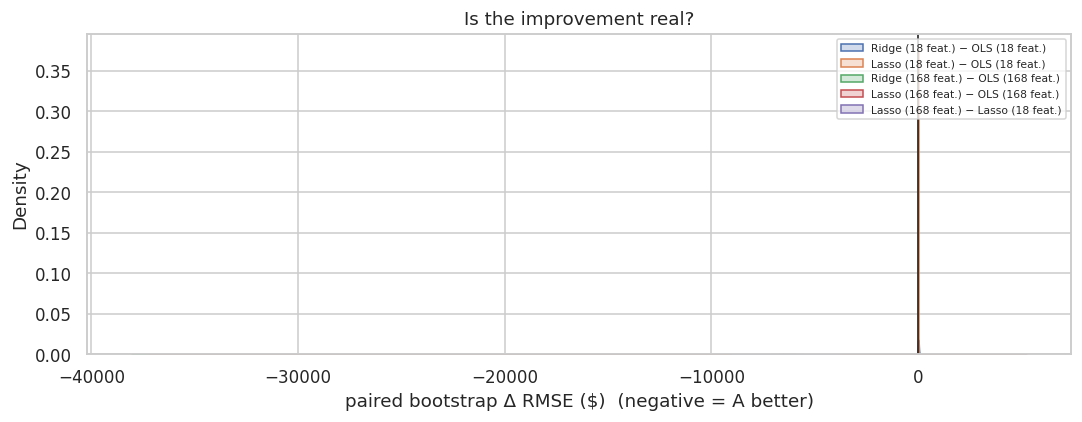

In [24]:
rng = np.random.default_rng(RANDOM_STATE)
y_t = y_test.values
B = 2000
idx = rng.integers(0, len(y_t), size=(B, len(y_t)))
boots = {k: np.sqrt(((y_t[idx] - p[idx]) ** 2).mean(axis=1)) * SCALE for k, p in test_pred.items()}

ci = pd.DataFrame({k: {"RMSE": np.sqrt(((y_t - test_pred[k]) ** 2).mean()) * SCALE,
                       "95% CI low": np.percentile(b, 2.5), "95% CI high": np.percentile(b, 97.5)} for k, b in boots.items()}).T
display(ci.style.format("{:,.0f}").set_caption("Test RMSE with 95% bootstrap CI ($)"))

comparisons = [("Ridge (18 feat.)", "OLS (18 feat.)"), ("Lasso (18 feat.)", "OLS (18 feat.)"),
               ("Ridge (168 feat.)", "OLS (168 feat.)"), ("Lasso (168 feat.)", "OLS (168 feat.)"),
               ("Lasso (168 feat.)", "Lasso (18 feat.)")]
rows = []
for a, b in comparisons:
    d = boots[a] - boots[b]
    rows.append({"Comparison (A − B)": f"{a}  −  {b}", "mean Δ RMSE ($)": d.mean(),
                 "95% CI low": np.percentile(d, 2.5), "95% CI high": np.percentile(d, 97.5),
                 "A better in % of resamples": 100 * (d < 0).mean()})
diff = pd.DataFrame(rows).set_index("Comparison (A − B)")
display(diff.style.format({"mean Δ RMSE ($)": "{:+,.0f}", "95% CI low": "{:+,.0f}", "95% CI high": "{:+,.0f}", "A better in % of resamples": "{:.1f}%"})
        .set_caption("Paired bootstrap of RMSE differences (negative = A is better)"))

fig, ax = plt.subplots(figsize=(10, 4))
for a, b in comparisons:
    sns.kdeplot(boots[a] - boots[b], fill=True, alpha=.25, label=f"{a} − {b}", ax=ax)
ax.axvline(0, color="k", lw=1); ax.set_xlabel("paired bootstrap Δ RMSE ($)  (negative = A better)")
ax.set_title("Is the improvement real?"); ax.legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.show()

## 10. What did L1 and L2 do to the coefficients?

All features are standardised, so coefficient magnitudes are directly comparable (change in value, in $100k, per one standard deviation of the feature).

,OLS,Ridge,Lasso
ocean_proximity_ISLAND,+0.9663,+0.6456,+0.9500
median_income,+0.8525,+0.8524,+0.8525
latitude,-0.8049,-0.8004,-0.8047
longitude,-0.7628,-0.7589,-0.7626
lat_x_lon,+0.5143,+0.5106,+0.5140
lat_sq,+0.3362,+0.3333,+0.3360
ocean_proximity_INLAND,-0.2554,-0.2575,-0.2555
pop_per_hh,-0.2432,-0.2433,-0.2432
lon_sq,+0.2320,+0.2299,+0.2318
bedroom_ratio,+0.2223,+0.2223,+0.2223


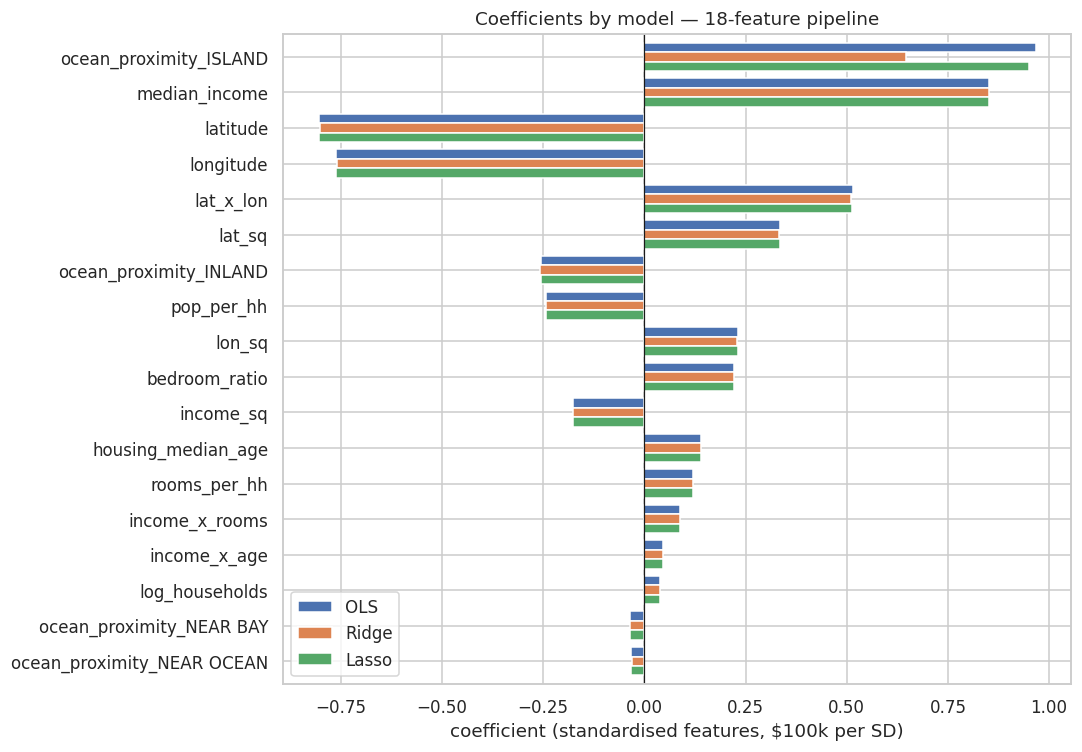

In [25]:
feat18 = ols[:-1].transform(X_train.head(2)).columns.tolist()
coefs = pd.DataFrame({k.split(" ")[0]: final_models[k].named_steps["model"].coef_
                      for k in ["OLS (18 feat.)", "Ridge (18 feat.)", "Lasso (18 feat.)"]}, index=feat18)
coefs = coefs.reindex(coefs["OLS"].abs().sort_values(ascending=False).index)
display(coefs.style.format("{:+.4f}").background_gradient(cmap="RdBu_r", axis=None, vmin=-.8, vmax=.8)
        .set_caption("18-feature pipeline: coefficients at the CV-best α"))

coefs.plot.barh(figsize=(10, 7), width=.8)
plt.gca().invert_yaxis(); plt.axvline(0, color="k", lw=.8)
plt.title("Coefficients by model — 18-feature pipeline"); plt.xlabel("coefficient (standardised features, $100k per SD)")
plt.tight_layout(); plt.show()

### 10.1 Sparsity and the "1-SE" model

Lasso's selling point is feature selection. The table shows, for both feature sets, how many coefficients survive and what the test error is at the CV-best α and at the more
aggressive **1-SE α** (the strongest penalty statistically tied with the best).

In [26]:
def refit_at(gs, alpha):
    return clone(gs.best_estimator_).set_params(model__alpha=alpha).fit(X_train, y_train)

rows = []
for tag, gs, kind in [("Ridge (18 feat.)", gs_ridge, "ridge"), ("Lasso (18 feat.)", gs_lasso, "lasso"),
                      ("Ridge (168 feat.)", gs_ridge_B, "ridge"), ("Lasso (168 feat.)", gs_lasso_B, "lasso")]:
    for rule, a in [("CV-best α", gs.best_params_["model__alpha"]), ("1-SE α", one_se_alpha(gs))]:
        m = refit_at(gs, a); c = m.named_steps["model"].coef_
        rows.append({"Model": tag, "Rule": rule, "α": a, "# features": len(c), "# non-zero": int((c != 0).sum()),
                     "Test RMSE ($)": metrics(y_test, m.predict(X_test))["RMSE"]})
sparsity = pd.DataFrame(rows).set_index(["Model", "Rule"])
display(sparsity.style.format({"α": "{:.3g}", "Test RMSE ($)": "{:,.0f}"}))

**Findings**

- **18-feature pipeline:** at the CV-best α almost nothing happens. Coefficients are nearly identical across OLS/Ridge/Lasso and Lasso keeps all 18. The one visible exception is `ocean_proximity_ISLAND`: only 5 block groups in the whole dataset are on islands, so its OLS coefficient (≈ +0.97, i.e. +$97k) is estimated from almost no data. **Ridge shrinks it by about a third** (to ≈ +0.65): shrinkage doing its job on a high-variance coefficient.
- **At the 1-SE α**, Lasso (18 feat.) zeroes 2 of 18 coefficients at a cost of ≈ $130 in test RMSE: a free simplification, but a tiny one.
- **168-feature pipeline:** Lasso keeps **97 of 168** coefficients at the CV-best α (89 at the 1-SE α, with test RMSE only ≈ $700 higher). Ridge keeps all 168 by construction and needs a much larger α (316 to 1,000) to control them.
  At the 1-SE point Ridge's heavier shrinkage costs more (test RMSE $60.1k vs $58.9k at its best α), whereas Lasso's extra sparsity is nearly free.

## 11. Residual error analysis

`residual = actual − predicted` (in dollars). A positive residual means the model *under*-predicted. We analyse all six models side by side first, then
run detailed diagnostics on the **model selected by cross-validation**.

### 11.1 Predicted vs actual

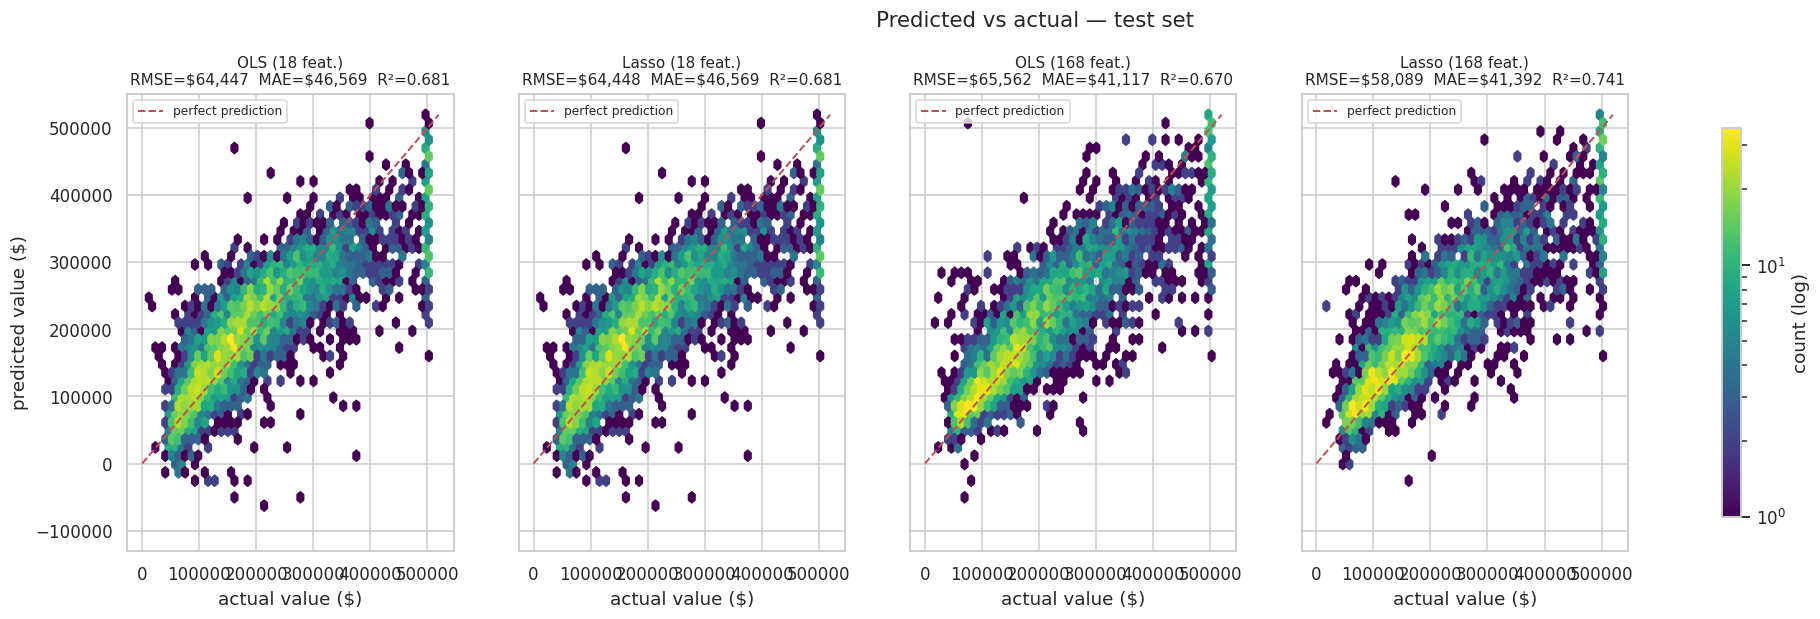

In [27]:
actual = test_df[TARGET].values                  # exact dollar values (avoids float round-trip through /SCALE)
resid = {k: actual - p * SCALE for k, p in test_pred.items()}
shown = ["OLS (18 feat.)", "Lasso (18 feat.)", "OLS (168 feat.)", "Lasso (168 feat.)"]

fig, axes = plt.subplots(1, 4, figsize=(22, 5.4), sharex=True, sharey=True)
lim = 5.2e5
for ax, k in zip(axes, shown):
    m = metrics(y_test, test_pred[k])
    hb = ax.hexbin(actual, test_pred[k] * SCALE, gridsize=45, cmap="viridis", mincnt=1, bins="log", extent=(0, lim, -1e5, lim))
    ax.plot([0, lim], [0, lim], "r--", lw=1.3, label="perfect prediction")
    ax.set_title(f"{k}\nRMSE=\${m['RMSE']:,.0f}  MAE=\${m['MAE']:,.0f}  R²={m['R²']:.3f}", fontsize=10)
    ax.set_xlabel("actual value ($)"); ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("predicted value ($)")
fig.colorbar(hb, ax=axes, label="count (log)", shrink=.85)
plt.suptitle("Predicted vs actual — test set", fontsize=14, y=1.02)
plt.show()

**Reading the plots.** All models share the vertical column at actual = $500,001: those block groups have a *censored* value (the true value is higher) but widely varying predictions. Note also that OLS on 168 features
(third panel) produces a few predictions far from the diagonal (some negative, some near $500k for homes worth far less). These extreme predictions inflate its RMSE; the regularised 168-feature model (right) reduces them.

### 11.2 Residual distributions

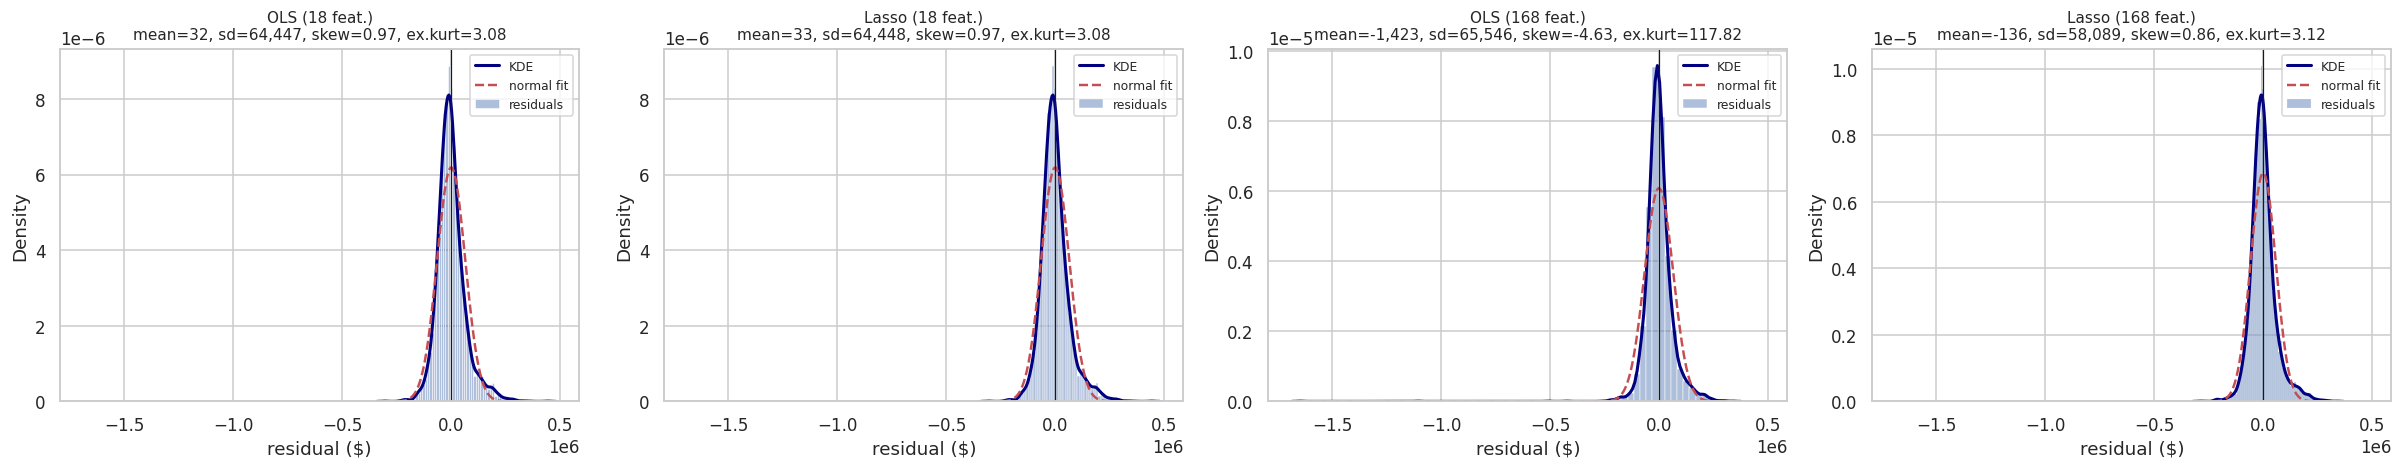

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4.6), sharex=True)
for ax, k in zip(axes, shown):
    r = resid[k]
    sns.histplot(r, bins=70, stat="density", color="C0", alpha=.45, ax=ax, label="residuals")
    sns.kdeplot(r, color="navy", lw=2, ax=ax, label="KDE")
    xs = np.linspace(r.min(), r.max(), 400)
    ax.plot(xs, stats.norm.pdf(xs, r.mean(), r.std()), "r--", lw=1.6, label="normal fit")
    ax.axvline(0, color="k", lw=.8)
    ax.set_title(f"{k}\nmean={r.mean():,.0f}, sd={r.std():,.0f}, skew={stats.skew(r):.2f}, ex.kurt={stats.kurtosis(r):.2f}", fontsize=10)
    ax.set_xlabel("residual ($)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 11.3 Detailed diagnostics for the selected model

Diagnosing: Lasso (168 feat.)


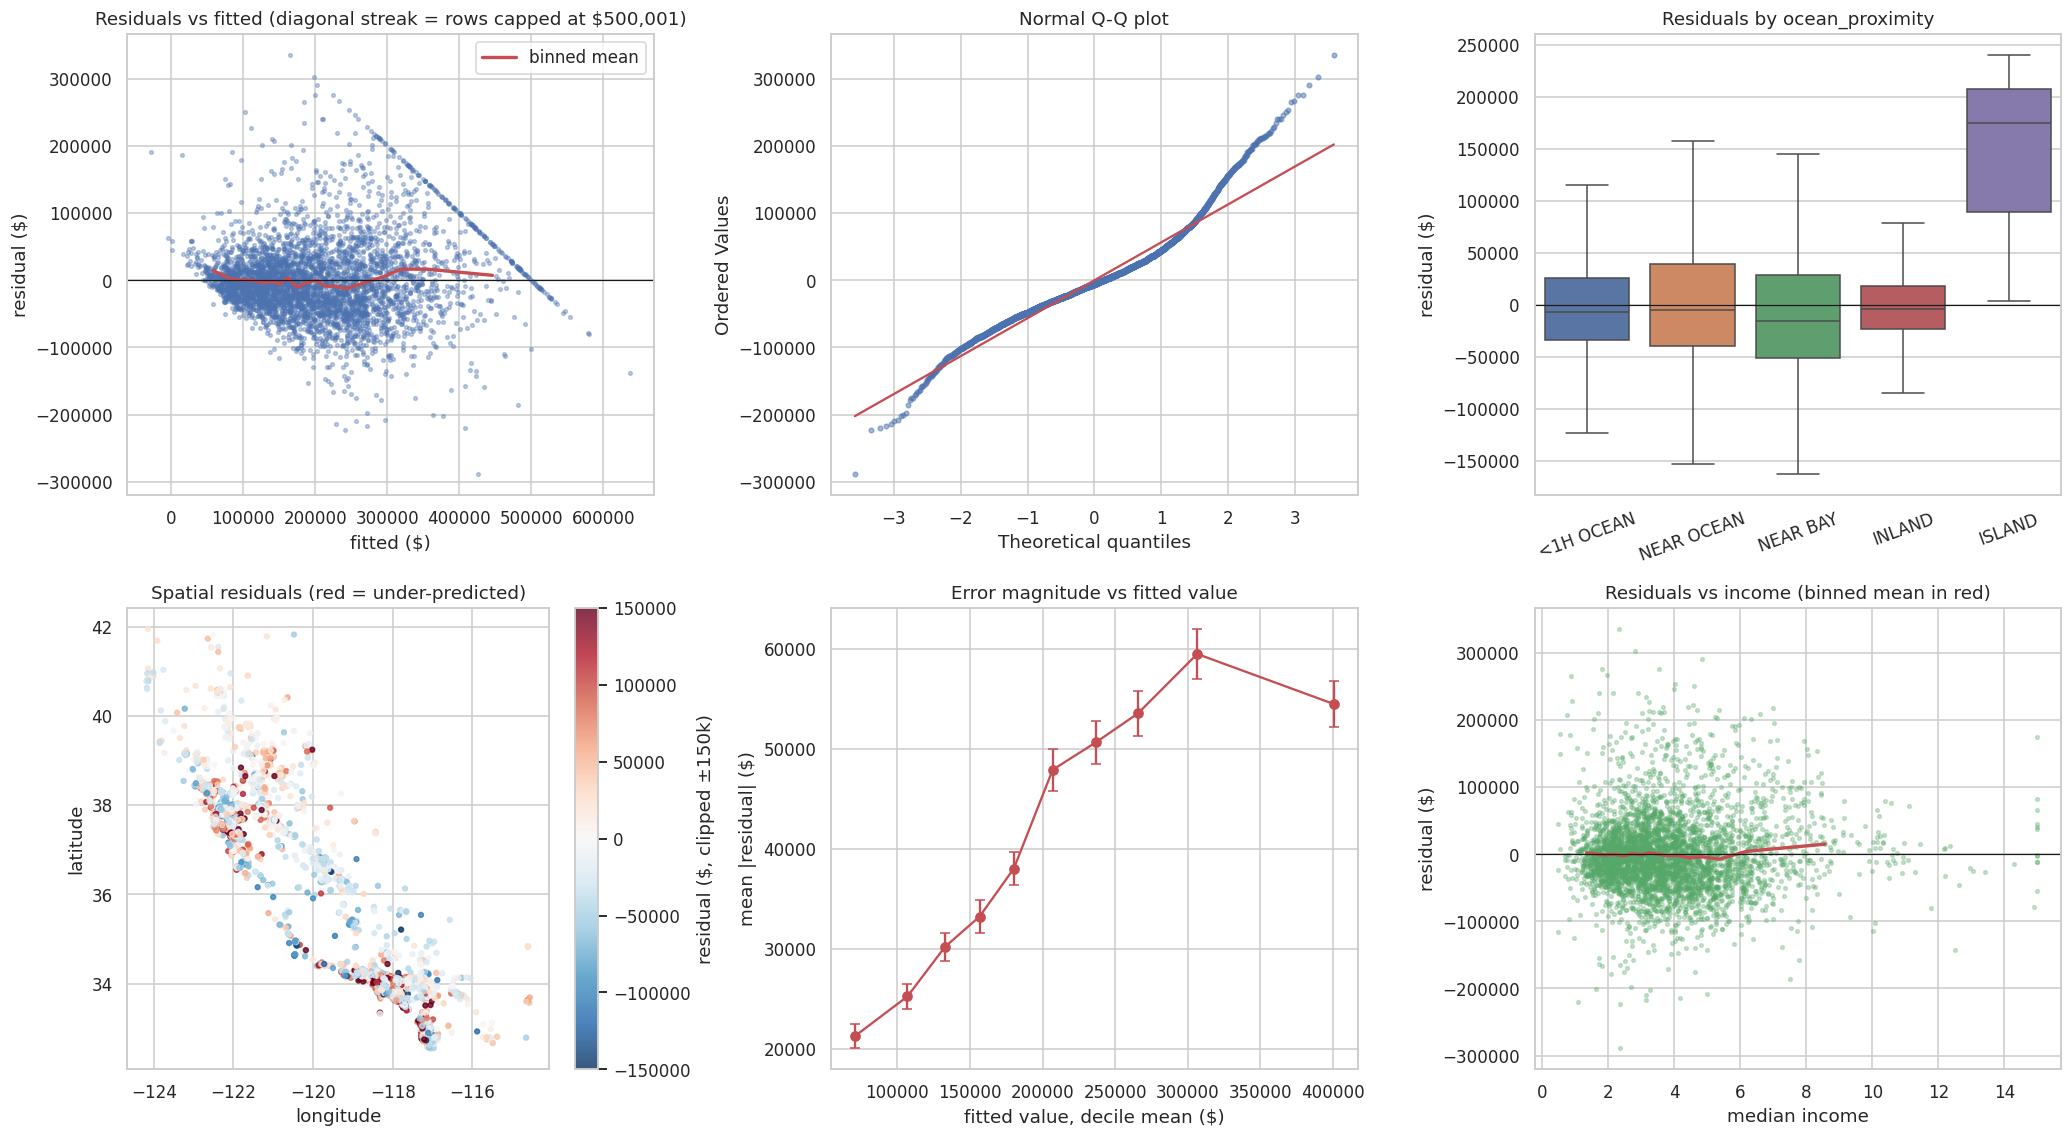

In [29]:
sel = best_name
r, p = resid[sel], test_pred[sel] * SCALE
print(f"Diagnosing: {sel}")

fig, axes = plt.subplots(2, 3, figsize=(19, 10.5))

ax = axes[0, 0]
ax.scatter(p, r, s=6, alpha=.35, color="C0")
bins_ = pd.qcut(p, 20)
ax.plot(pd.Series(p).groupby(bins_, observed=True).mean(), pd.Series(r).groupby(bins_, observed=True).mean(), "r-", lw=2.2, label="binned mean")
ax.axhline(0, color="k", lw=.8); ax.set_xlabel("fitted ($)"); ax.set_ylabel("residual ($)")
ax.set_title("Residuals vs fitted (diagonal streak = rows capped at \$500,001)"); ax.legend()

ax = axes[0, 1]
stats.probplot(r, dist="norm", plot=ax)
ax.get_lines()[0].set_markersize(3); ax.get_lines()[0].set_alpha(.5)
ax.set_title("Normal Q-Q plot")

ax = axes[0, 2]
sns.boxplot(x=X_test["ocean_proximity"].values, y=r, ax=ax, showfliers=False, hue=X_test["ocean_proximity"].values, legend=False)
ax.axhline(0, color="k", lw=.8); ax.set_title("Residuals by ocean_proximity"); ax.tick_params(axis="x", rotation=20)
ax.set_xlabel(""); ax.set_ylabel("residual ($)")

ax = axes[1, 0]
sc = ax.scatter(X_test["longitude"], X_test["latitude"], c=np.clip(r, -1.5e5, 1.5e5), cmap="RdBu_r", s=10, alpha=.8)
plt.colorbar(sc, ax=ax, label="residual ($, clipped ±150k)")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_title("Spatial residuals (red = under-predicted)")

ax = axes[1, 1]
dec = pd.DataFrame({"fitted": p, "abs_resid": np.abs(r)}); dec["bin"] = pd.qcut(dec.fitted, 10)
g = dec.groupby("bin", observed=True).agg(fitted=("fitted", "mean"), mae=("abs_resid", "mean"), sd=("abs_resid", "std"))
ax.errorbar(g.fitted, g.mae, yerr=g.sd / np.sqrt(len(dec) / 10), fmt="o-", color="C3", capsize=3)
ax.set_xlabel("fitted value, decile mean ($)"); ax.set_ylabel("mean |residual| ($)"); ax.set_title("Error magnitude vs fitted value")

ax = axes[1, 2]
ax.scatter(X_test["median_income"], r, s=6, alpha=.3, color="C2")
bi = pd.qcut(X_test["median_income"], 15)
ax.plot(X_test["median_income"].groupby(bi, observed=True).mean(), pd.Series(r, index=X_test.index).groupby(bi, observed=True).mean(), "r-", lw=2.2)
ax.axhline(0, color="k", lw=.8); ax.set_xlabel("median income"); ax.set_ylabel("residual ($)")
ax.set_title("Residuals vs income (binned mean in red)")
plt.tight_layout(); plt.show()

In [30]:
# Quantify the diagnostics
capped = actual >= cap_val
nt = stats.normaltest(r)
print(f"D'Agostino normality test: statistic={nt.statistic:,.0f}, p={nt.pvalue:.2e}")
print(f"corr(|residual|, fitted) = {np.corrcoef(np.abs(r), p)[0, 1]:.3f}")
print(f"skew = {stats.skew(r):.2f}, excess kurtosis = {stats.kurtosis(r):.2f}")
print()
tab = pd.DataFrame({
    "rows": [len(r), (~capped).sum(), capped.sum()],
    "mean residual ($)": [r.mean(), r[~capped].mean(), r[capped].mean()],
    "RMSE ($)": [np.sqrt((r**2).mean()), np.sqrt((r[~capped]**2).mean()), np.sqrt((r[capped]**2).mean())],
    "MAE ($)": [np.abs(r).mean(), np.abs(r[~capped]).mean(), np.abs(r[capped]).mean()],
}, index=["all test rows", "uncapped rows only", f"capped rows (value = ${cap_val:,.0f})"])
display(tab.style.format({"rows": "{:,.0f}", "mean residual ($)": "{:,.0f}", "RMSE ($)": "{:,.0f}", "MAE ($)": "{:,.0f}"}))
print("Uncapped-only R²:", round(r2_score(actual[~capped], p[~capped]), 4), "| all-rows R²:", round(r2_score(actual, p), 4))

# error by ocean_proximity and by price band
by_cat = pd.DataFrame({"cat": X_test["ocean_proximity"].values, "r": r}).groupby("cat")["r"].agg(["count", "mean", "median", "std"])
display(by_cat.style.format({"mean": "{:,.0f}", "median": "{:,.0f}", "std": "{:,.0f}"}).set_caption("Residuals by ocean_proximity ($)"))

# compare spatial structure of the residuals across models: Moran-like check using nearest-neighbour residual correlation
from sklearn.neighbors import NearestNeighbors
coords = X_test[["longitude", "latitude"]].values
nn = NearestNeighbors(n_neighbors=6).fit(coords)
_, nb_idx = nn.kneighbors(coords)
def spatial_autocorr(res):
    z = (res - res.mean()) / res.std()
    return float(np.mean(z * z[nb_idx[:, 1:]].mean(axis=1)))
sp = pd.Series({k: spatial_autocorr(resid[k]) for k in resid}, name="neighbour residual correlation")
display(sp.to_frame().style.format("{:.3f}").set_caption("Spatial autocorrelation of residuals (0 = none; higher = geography left unexplained)"))

D'Agostino normality test: statistic=699, p=1.77e-152
corr(|residual|, fitted) = 0.268
skew = 0.86, excess kurtosis = 3.12



,rows,mean residual ($),RMSE ($),MAE ($)
all test rows,"4,128",-136,"58,089","41,392"
uncapped rows only,"3,949","-4,021","53,638","39,002"
"capped rows (value = $500,001)",179,"85,568","119,765","94,117"


Uncapped-only R²: 0.6983 | all-rows R²: 0.7411


,count,mean,median,std
cat,,,,
<1H OCEAN,1859,-125,"-6,500","58,283"
INLAND,1289,"-1,041","-3,703","45,237"
ISLAND,3,"139,672","175,076","122,320"
NEAR BAY,443,"-5,357","-15,654","69,352"
NEAR OCEAN,534,"5,556","-5,395","71,659"


,neighbour residual correlation
OLS (18 feat.),0.362
Ridge (18 feat.),0.362
Lasso (18 feat.),0.362
OLS (168 feat.),0.227
Ridge (168 feat.),0.322
Lasso (168 feat.),0.326


### 11.4 What the residual analysis tells us (model: Lasso, 168 features)

| Diagnostic | Finding | Implication |
|---|---|---|
| Residual distribution & Q-Q | Centred (mean ≈ −$140) but **right-skewed (skew 0.86) with heavy tails (excess kurtosis 3.1)**; the Q-Q plot bends away from the line in both tails, more on the high side | Point predictions are unbiased overall, but classical OLS standard errors and Gaussian prediction intervals would be wrong |
| Residuals vs fitted | The binned mean stays close to zero (with a modest positive bump near $300–350k). The **diagonal streak** is the censored rows: for them `residual = 500,001 − fitted` exactly | The streak is an artefact of the dataset's cap, not of the model |
| \|residual\| vs fitted | Error magnitude rises steadily with price: mean \|residual\| ≈ $21k in the cheapest decile, ≈ $59k around $300k (corr ≈ 0.27) | **Heteroscedastic** errors; errors are partly multiplicative, which motivates the log-target experiment |
| Capped rows (179 of 4,128 test rows) | Mean residual **+$85.6k** and RMSE $119.8k on these rows; excluding them lowers overall RMSE from $58.1k to $53.6k | Censoring biases the fit and inflates the headline RMSE. (Uncapped-only R² is lower, 0.698 vs 0.741, only because removing the high-value tail also shrinks the target's variance; it is not a worse model.) |
| By `ocean_proximity` | Medians are near zero (`NEAR BAY` slightly negative); spread is wider on the coast (SD ≈ $69–72k for NEAR BAY / NEAR OCEAN) than inland (≈ $45k). `ISLAND` has only 3 test rows (+$140k mean) | Coastal prices are intrinsically harder to predict from these features |
| Spatial residual map | Residuals are visibly clustered (patches of red and blue in the Bay Area and Los Angeles basin). A neighbour-residual correlation of ≈ 0.33 confirms it (0.36 for the 18-feature models) | The polynomial terms only partly capture geography. Neighbourhood-aware features (KNN price, spatial clusters) are the obvious next step |

One more observation from the spatial table: **OLS (168) has the *lowest* residual spatial correlation (0.23)**, so the extra flexibility really does fit geography better, but it buys that with the wild extrapolation errors seen above.
Regularisation gives up a little of the spatial fit (0.32) in exchange for stability.

## 12. Extension: log-transformed target

If the residual analysis shows error growing with price, errors are probably *multiplicative*; modelling `log(value)` and back-transforming is the textbook fix.
We apply it to the CV-selected model and judge it on cross-validated RMSE **and** MAE (MAE is robust to the few extreme predictions that `exp()` can produce).

,CV RMSE ($),worst-fold RMSE ($),CV MAE ($),Test RMSE ($),Test MAE ($),Test R²
Model,,,,,,
"Lasso (168 feat.), raw target","60,104","61,814","41,897","58,089","41,392",0.7411
"Lasso (168 feat.), log target","707,401","3,289,339","53,209","60,661","41,627",0.7177
"Ridge (18 feat.), raw target","65,067","65,971","46,726","64,463","46,578",0.6812
"Ridge (18 feat.), log target","64,195","65,474","43,602","63,810","43,526",0.6876


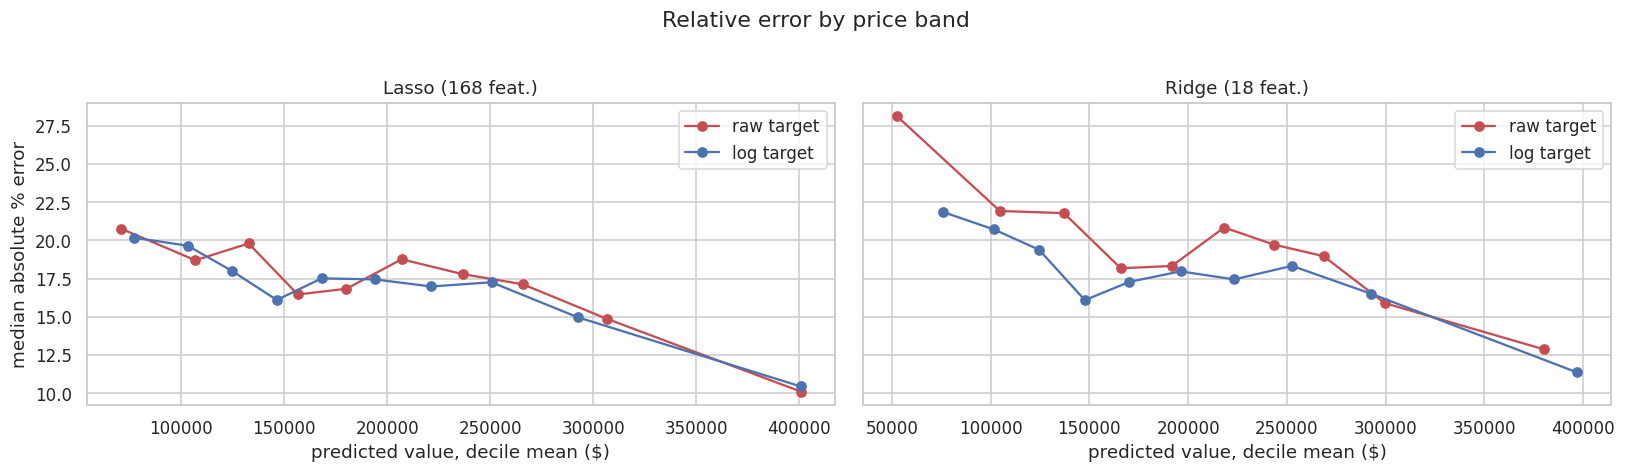

In [31]:
bases = {best_name: final_models[best_name], "Ridge (18 feat.)": final_models["Ridge (18 feat.)"]}   # high-capacity vs low-capacity

def cv_both(est):
    rm, ma = [], []
    for tr_i, va_i in cv5.split(X_train):
        m = clone(est).fit(X_train.iloc[tr_i], y_train.iloc[tr_i]); p_ = m.predict(X_train.iloc[va_i])
        rm.append(mean_squared_error(y_train.iloc[va_i], p_) ** .5 * SCALE); ma.append(mean_absolute_error(y_train.iloc[va_i], p_) * SCALE)
    return np.array(rm), np.array(ma)

rows, fitted_pairs = [], {}
for bname, bmodel in bases.items():
    pair = {}
    for tag, est in [("raw target", clone(bmodel)),
                     ("log target", TransformedTargetRegressor(regressor=clone(bmodel), func=np.log, inverse_func=np.exp))]:
        rm, ma = cv_both(est)
        m = clone(est).fit(X_train, y_train); pred = m.predict(X_test); t = metrics(y_test, pred)
        pair[tag] = pred * SCALE
        rows.append({"Model": f"{bname}, {tag}", "CV RMSE ($)": rm.mean(), "worst-fold RMSE ($)": rm.max(), "CV MAE ($)": ma.mean(),
                     "Test RMSE ($)": t["RMSE"], "Test MAE ($)": t["MAE"], "Test R²": t["R²"]})
    fitted_pairs[bname] = pair
logcmp = pd.DataFrame(rows).set_index("Model")
display(logcmp.style.format({c: "{:,.0f}" for c in logcmp.columns if c != "Test R²"} | {"Test R²": "{:.4f}"}))

# relative error by predicted-value decile: flat = multiplicative errors have been equalised
fig, axes = plt.subplots(1, len(bases), figsize=(7.5 * len(bases), 4.2), sharey=True)
for ax, (bname, pair) in zip(np.atleast_1d(axes), fitted_pairs.items()):
    for tag, c in [("raw target", "C3"), ("log target", "C0")]:
        pp = pair[tag]
        d = pd.DataFrame({"pp": pp, "ape": np.abs(actual - pp) / actual * 100}); d["b"] = pd.qcut(d.pp, 10)
        g = d.groupby("b", observed=True).agg(x=("pp", "mean"), y=("ape", "median"))
        ax.plot(g.x, g.y, "o-", color=c, label=tag)
    ax.set_xlabel("predicted value, decile mean ($)"); ax.set_title(bname); ax.legend()
np.atleast_1d(axes)[0].set_ylabel("median absolute % error")
plt.suptitle("Relative error by price band", y=1.02); plt.tight_layout(); plt.show()

**Read-out: the log target helps a stable model and wrecks a flexible one.**

- **Ridge, 18 features (low capacity):** the log target improves every measure. CV RMSE falls from $65.1k to $64.2k, CV MAE from $46.7k to $43.6k, and on the test set RMSE from $64.5k to $63.8k and MAE from $46.6k to $43.5k (R² 0.681 → 0.688). The MAE gain (≈ $3k) is much larger than the RMSE gain, which fits the diagnosis: it mostly improves the typical case and relative error, as expected when errors are multiplicative.
- **Lasso, 168 features (high capacity):** it fails badly. The cubic polynomial occasionally extrapolates to a large positive value in log space, and `exp()` turns that into an enormous dollar error. CV RMSE jumps to $707k (worst fold $3.3M), CV MAE rises from $41.9k to $53.2k, and test RMSE rises from $58.1k to $60.7k.

A log-model also predicts the conditional *median*, not the mean, so its dollar RMSE is not guaranteed to improve even when relative errors do. The lesson is that a back-transformed target needs bounded or clipped predictions before it can be combined with high-capacity models.
Because the raw-target Lasso (168) is better on every metric that matters here (and was chosen by CV), it remains the primary model; the log-target Ridge is a good, safer alternative if relative error matters more than dollar RMSE.

## 13. Extension: regularisation as a small-data tool (18-feature pipeline)

On the full training set the 18-feature OLS, Ridge and Lasso are interchangeable. Regularisation is a **variance-reduction** tool, so its benefit should reappear when data is scarce.
We repeatedly sub-sample the training set to `n` rows, fit OLS / RidgeCV / LassoCV (α chosen by internal CV) and score on the *same* untouched test set.

model,Lasso,OLS,Ridge
n,,,
40,"77,551","100,777","80,908"
80,"72,510","81,505","73,952"
160,"68,960","70,911","69,407"
320,"68,100","68,462","68,110"
1000,"65,330","65,185","65,182"
4000,"64,761","64,762","64,752"
16512,"64,450","64,447","64,460"


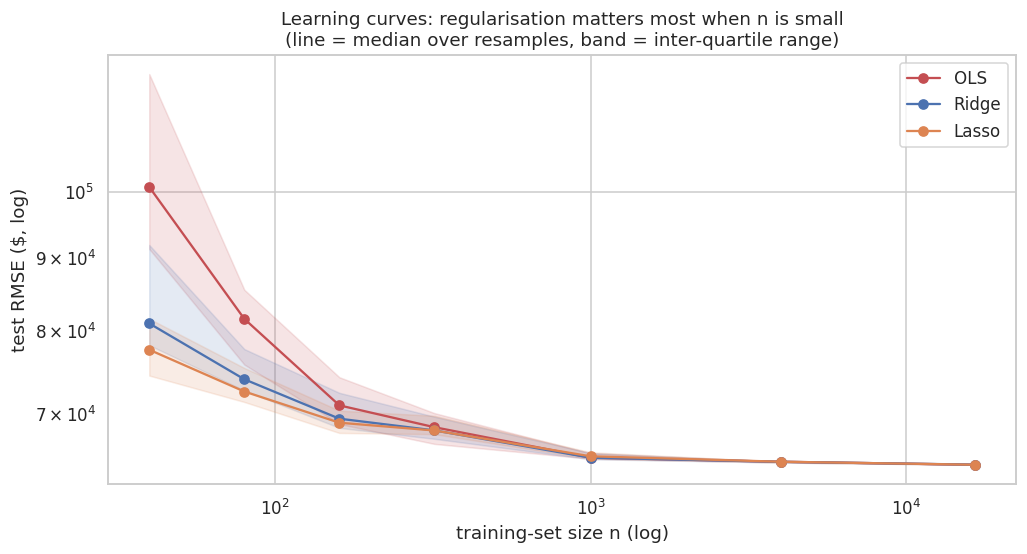

In [32]:
sizes   = [40, 80, 160, 320, 1000, 4000]
repeats = {40: 15, 80: 15, 160: 12, 320: 10, 1000: 6, 4000: 3}

def models_for_size():
    return {
        "OLS":   make_pipe(LinearRegression()),
        "Ridge": make_pipe(RidgeCV(alphas=np.logspace(-3, 4, 30))),
        "Lasso": make_pipe(LassoCV(alphas=np.logspace(-5, 0, 40), cv=5, max_iter=50_000, random_state=RANDOM_STATE)),
    }

rng = np.random.default_rng(0)
rec = []
for n in sizes:
    for rep in range(repeats[n]):
        idx = rng.choice(len(X_train), n, replace=False)
        Xs, ys = X_train.iloc[idx], y_train.iloc[idx]
        for name, mdl in models_for_size().items():
            mdl.fit(Xs, ys)
            rec.append({"n": n, "model": name, "RMSE": metrics(y_test, mdl.predict(X_test))["RMSE"]})
for name, mdl in models_for_size().items():
    mdl.fit(X_train, y_train)
    rec.append({"n": len(X_train), "model": name, "RMSE": metrics(y_test, mdl.predict(X_test))["RMSE"]})
lc = pd.DataFrame(rec)

summ = lc.groupby(["n", "model"])["RMSE"].agg(["median", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
summ.columns = ["median", "q25", "q75"]
display(summ["median"].unstack().style.format("{:,.0f}").set_caption("Median test RMSE ($) by training-set size"))

fig, ax = plt.subplots(figsize=(9.5, 5.2))
for name, c in zip(["OLS", "Ridge", "Lasso"], ["C3", "C0", "C1"]):
    s = summ.xs(name, level="model")
    ax.plot(s.index, s["median"], "o-", color=c, label=name)
    ax.fill_between(s.index, s["q25"], s["q75"], color=c, alpha=.15)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("training-set size n (log)"); ax.set_ylabel("test RMSE ($, log)")
ax.set_title("Learning curves: regularisation matters most when n is small\n(line = median over resamples, band = inter-quartile range)")
ax.legend(); plt.tight_layout(); plt.show()

## 14. Conclusions

1. **Final result.** The best model by cross-validation, **Lasso on 168 polynomial features**, reaches **test RMSE ≈ $58.1k, MAE ≈ $41.4k, R² ≈ 0.741**, versus ≈ $64.4k / $46.6k / 0.681 for the 18-feature models (which are indistinguishable from each other).
   The test set was used only once, after every choice was made with cross-validation.
2. **Feature engineering did most of the work on the 18-feature pipeline.** Imputation, per-household ratios (log-transformed), centred interactions and lat/lon polynomials improved CV RMSE by ≈ $4k over the raw features; naïve ratios without a log transform made things much worse.
3. **Imputation mattered more than expected.** KNN/iterative imputation beat median imputation in 5/5 folds (≈ $0.8k) because median-filled `total_bedrooms` creates implausible `bedroom_ratio` values for 40 % of the imputed rows, versus about 1 % with KNN.
4. **Regularisation is not automatically useful.** On 18 well-conditioned features and ~16.5k rows, OLS ≈ Ridge ≈ Lasso (test RMSE differences of $16 or less, bootstrap intervals straddling zero). Its value appears when the feature space is rich and collinear: on 168 features Ridge improves CV RMSE by ≈ $5.7k and Lasso by ≈ $7.8k over OLS.
   On the *test* set the 168-feature gain over OLS is similar in size (≈ $6.5–7.3k), but the paired-bootstrap 95 % interval narrowly includes zero (about 90–93 % of resamples favour the regularised model), because OLS's test RMSE hinges on a handful of extreme predictions. Notably OLS (168) has the *lowest typical error* (test MAE ≈ $41.1k): regularisation helps the tail, not the median case.
5. **Lasso vs Ridge.** Lasso was better on CV ($60.1k vs $62.3k) and sparser (97/168 non-zero; 89/168 at the 1-SE α with only ≈ $0.7k worse test RMSE). Ridge keeps every coefficient.
6. **Regularisation is a small-data tool too.** With n = 40 training rows OLS's test RMSE is ≈ $101k vs ≈ $78k for Lasso and ≈ $81k for Ridge; the gap closes as n grows and is negligible by ≈ 1,000 rows.
7. **Residual analysis** shows heavy-tailed, right-skewed, heteroscedastic errors, a systematic problem with the $500k-capped rows (mean residual +$86k there), larger errors on the coast, and **unexplained spatial structure**.
8. **Next steps**: spatial features (KNN/cluster-based neighbourhood prices, distance to coast and major cities), treating the capped rows as censored (or excluding them from training), gradient-boosted trees as a non-linear benchmark, and an elastic net to combine L1 sparsity with L2 stability.